# Local RGB-D Grasp Refinement

Close-range (approximately 0.25-0.35 m) local refinement for one target at a time.

This notebook:

- supports live aligned RealSense RGB-D capture and offline RGB/raw-depth input;
- outputs pixel coordinates and `camera_color_optical_frame` coordinates only;
- does **not** transform points into robot base frame because hand-eye calibration is not available;
- never uses a depth colormap image for 3D calculation.

For base holes, the pixel is the center of the true black hole, while depth is sampled from the surrounding silver ring.

## Part 1: Imports and parameters

In [57]:
from __future__ import annotations

import csv
import json
import math
import time
from pathlib import Path
from typing import Any

import cv2
import matplotlib.pyplot as plt
import numpy as np

try:
    import pyrealsense2 as rs
    REALSENSE_AVAILABLE = True
except ImportError:
    rs = None
    REALSENSE_AVAILABLE = False

CAMERA_FRAME_ID = "camera_color_optical_frame"
VALID_TARGET_TYPES = {
    "base", "gear_large", "gear_small", "gear_compound",
    "shaft_large", "shaft_small", "screw",
}

# Input selection.
INPUT_MODE = "offline"  # "offline" or "live"
TARGET_TYPE = "gear_large"  # Must be in VALID_TARGET_TYPES.

# Painted-black grasp-marker samples:
# gear_small:    20260610_141104
# screw:         20260610_141142
# gear_large:    20260610_141237
# gear_compound: 20260610_141258
OFFLINE_COLOR_PATH = Path("realsense_pic/realsense_color_20260615_170349.png")
OFFLINE_DEPTH_PATH = Path("realsense_pic/realsense_depth_raw_20260615_170349.npy")

# Existing saved RealSense raw files are uint16 millimeters. Multiplying by
# 0.001 converts them to meters. Set to 1.0 when the .npy already stores meters.
OFFLINE_DEPTH_SCALE_TO_M = 0.001

# Fill these with the color intrinsics captured at the same resolution.
# Keep None to test pixel detection without producing misleading 3D values.
OFFLINE_INTRINSICS = None
# Example structure only:
# OFFLINE_INTRINSICS = {"fx": ..., "fy": ..., "ppx": ..., "ppy": ...}

LIVE_WIDTH = 640
LIVE_HEIGHT = 480
LIVE_FPS = 30
LIVE_WARMUP_FRAMES = 20

OUTPUT_DIR = Path("local_rgbd_refinement_results")
OUTPUT_JSON = OUTPUT_DIR / "local_refinement_result.json"
OUTPUT_CSV = OUTPUT_DIR / "local_refinement_result.csv"
OUTPUT_ANNOTATED = OUTPUT_DIR / "local_refinement_annotated.png"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Red target segmentation.
RED_LOW_1 = np.array([0, 70, 40], dtype=np.uint8)
RED_HIGH_1 = np.array([12, 255, 255], dtype=np.uint8)
RED_LOW_2 = np.array([165, 70, 40], dtype=np.uint8)
RED_HIGH_2 = np.array([179, 255, 255], dtype=np.uint8)
RED_OPEN_KERNEL = 3
RED_CLOSE_KERNEL = 9
GEAR_MIN_AREA_PX = 2500
SCREW_MIN_AREA_PX = 120
SCREW_MAX_AREA_PX = 6000
SCREW_MAX_DIM_PX = 130

# Black target segmentation.
BLACK_MAX_VALUE = 95

# Painted grasp-marker segmentation. This is separate from shaft segmentation:
# gear markers are thin black strips, while the screw marker is a wider patch.
BLACK_GRASP_MARKER_MAX_VALUE = 100
BLACK_GRASP_MARKER_OPEN_KERNEL = 3
BLACK_GRASP_MARKER_CLOSE_KERNEL = 3
GEAR_BLACK_MARKER_CENTER_RADIUS_RATIO = 0.56
GEAR_BLACK_MARKER_MIN_AREA_PX = 100
GEAR_BLACK_MARKER_MAX_AREA_PX = 1800
GEAR_BLACK_MARKER_MIN_ASPECT_RATIO = 4.0
GEAR_BLACK_MARKER_MIN_LONG_SIDE_PX = 20
GEAR_BLACK_MARKER_MAX_LONG_SIDE_PX = 100
GEAR_BLACK_MARKER_MAX_PARALLEL_ANGLE_DEG = 18
GEAR_BLACK_MARKER_MAX_AXIS_DOT = 0.42
GEAR_BLACK_MARKER_MIN_SEPARATION_PX = 20
SCREW_BLACK_MARKER_MIN_AREA_PX = 250
SCREW_BLACK_MARKER_MAX_AREA_PX = 5000
SCREW_BLACK_MARKER_MIN_ASPECT_RATIO = 1.30
SCREW_BLACK_MARKER_MAX_CENTER_OFFSET_RATIO = 0.42
BLACK_MARKER_EDGE_RATIO = 0.46

SHAFT_MIN_AREA_PX = 350
SHAFT_MAX_AREA_PX = 30000
SHAFT_MIN_RECTANGULARITY = 0.55

# Neutral silver base segmentation.
SILVER_MAX_SATURATION = 75
SILVER_MIN_VALUE = 45
SILVER_MAX_VALUE = 210
SILVER_MAX_L = 205
SILVER_LAB_A_TOL = 34
SILVER_LAB_B_TOL = 42
BASE_MIN_AREA_PX = 5000

# Base black-hole filtering.
HOLE_MIN_AREA_PX = 180
HOLE_MAX_AREA_PX = 8000
HOLE_MIN_RADIUS_PX = 18
HOLE_MAX_RADIUS_PX = 55
HOLE_MIN_CIRCULARITY = 0.68
HOLE_MIN_ASPECT_RATIO = 0.55
HOLE_MIN_SILVER_RING_FRACTION = 0.12
HOLE_IMAGE_BORDER_MARGIN_PX = 8
HOLE_RING_INNER_PAD_PX = 3
HOLE_RING_OUTER_PAD_PX = 13

# Depth sampling and top-surface extraction.
POINT_DEPTH_WINDOW = 7
MIN_VALID_DEPTH_M = 0.05
MAX_VALID_DEPTH_M = 2.0
TOP_SURFACE_PERCENTILE = 20
TOP_SURFACE_MIN_VALID_COUNT = 50
TOP_SURFACE_OPEN_KERNEL = 3
TOP_SURFACE_CLOSE_KERNEL = 7
TOP_SURFACE_DETREND_PLANE = True

# Gear top protrusion selection. The inner radius explicitly excludes outer teeth.
GEAR_INNER_RADIUS_RATIO = 0.46
GEAR_TOP_COMPONENT_MIN_AREA_PX = 80
GEAR_TOP_COMPONENT_ERODE_PX = 3
GEAR_MIN_COMPONENT_SEPARATION_PX = 12

# Screw top-bar grasp geometry.
SCREW_TOP_MIN_AREA_PX = 80
SCREW_TOP_CENTER_ROI_RATIO = 0.55
SCREW_TOP_DEPTH_TOLERANCE_M = 0.0005
SCREW_TOP_MIN_ASPECT_RATIO = 1.25
SCREW_TOP_MAX_CENTER_OFFSET_RATIO = 0.22
SCREW_GRASP_SHORT_AXIS_RATIO = 0.45
SCREW_MIN_GRASP_SEPARATION_PX = 8

DRAW_COLORS = {
    "contour": (0, 220, 0),
    "center": (255, 255, 0),
    "left": (255, 100, 20),
    "right": (20, 20, 255),
    "midpoint": (0, 255, 255),
    "yaw": (255, 0, 255),
    "hole": (255, 255, 0),
    "top_surface": (255, 0, 255),
    "selected_top": (255, 255, 0),
}

print("pyrealsense2 available:", REALSENSE_AVAILABLE)
print("Target:", TARGET_TYPE)
print("3D output frame:", CAMERA_FRAME_ID)


pyrealsense2 available: True
Target: gear_large
3D output frame: camera_color_optical_frame


## Part 2: RealSense aligned RGB-D capture

In [58]:
def start_realsense_pipeline(
    width: int = LIVE_WIDTH,
    height: int = LIVE_HEIGHT,
    fps: int = LIVE_FPS,
):
    """Start color and depth streams and create depth-to-color alignment."""
    if not REALSENSE_AVAILABLE:
        raise RuntimeError("pyrealsense2 is unavailable; use offline mode.")
    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(rs.stream.color, width, height, rs.format.bgr8, fps)
    config.enable_stream(rs.stream.depth, width, height, rs.format.z16, fps)
    profile = pipeline.start(config)
    align_to_color = rs.align(rs.stream.color)
    depth_scale = float(profile.get_device().first_depth_sensor().get_depth_scale())
    return pipeline, align_to_color, depth_scale


def capture_aligned_rgbd(
    pipeline,
    align_to_color,
    depth_scale: float,
    warmup_frames: int = LIVE_WARMUP_FRAMES,
):
    """Capture BGR, aligned raw depth in meters, and true color intrinsics."""
    frames = None
    for _ in range(max(1, int(warmup_frames))):
        frames = pipeline.wait_for_frames()
    aligned_frames = align_to_color.process(frames)
    color_frame = aligned_frames.get_color_frame()
    depth_frame = aligned_frames.get_depth_frame()
    if not color_frame or not depth_frame:
        raise RuntimeError("Could not obtain aligned color and depth frames.")

    color_bgr = np.asanyarray(color_frame.get_data()).copy()
    depth_raw = np.asanyarray(depth_frame.get_data()).copy()
    depth_m = depth_raw.astype(np.float32) * float(depth_scale)
    color_intr = color_frame.profile.as_video_stream_profile().intrinsics
    intrinsics = {
        "fx": float(color_intr.fx),
        "fy": float(color_intr.fy),
        "ppx": float(color_intr.ppx),
        "ppy": float(color_intr.ppy),
    }
    return color_bgr, depth_m, intrinsics


def capture_live_once():
    """Safely capture one aligned frame set and stop the camera."""
    pipeline, align_to_color, depth_scale = start_realsense_pipeline()
    try:
        return capture_aligned_rgbd(pipeline, align_to_color, depth_scale)
    finally:
        pipeline.stop()


## Part 3: Depth utilities and pixel-to-camera conversion

Only aligned raw depth in meters is accepted. A depth colormap is visualization and must never be passed to these functions.

In [59]:
def _valid_depth_values(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=np.float64)
    return values[
        np.isfinite(values)
        & (values >= MIN_VALID_DEPTH_M)
        & (values <= MAX_VALID_DEPTH_M)
    ]


def get_median_depth_around_pixel(
    depth_image_m, u, v, window_size=7
):
    if depth_image_m is None:
        return None, 0
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2:
        raise ValueError("depth_image_m must be a 2D aligned raw depth array.")
    size = max(1, int(window_size))
    if size % 2 == 0:
        size += 1
    half = size // 2
    u0, v0 = int(round(float(u))), int(round(float(v)))
    x0, x1 = max(0, u0 - half), min(depth.shape[1], u0 + half + 1)
    y0, y1 = max(0, v0 - half), min(depth.shape[0], v0 + half + 1)
    if x0 >= x1 or y0 >= y1:
        return None, 0
    valid = _valid_depth_values(depth[y0:y1, x0:x1])
    return (float(np.median(valid)), int(valid.size)) if valid.size else (None, 0)


def get_median_depth_in_mask(depth_image_m, mask):
    if depth_image_m is None:
        return None, 0
    depth = np.asarray(depth_image_m)
    mask_array = np.asarray(mask)
    if depth.ndim != 2 or mask_array.shape != depth.shape:
        raise ValueError("Depth and mask must be same-size 2D arrays.")
    valid = _valid_depth_values(depth[mask_array > 0])
    return (float(np.median(valid)), int(valid.size)) if valid.size else (None, 0)


def get_ring_median_depth(
    depth_image_m, u, v, r_inner, r_outer, support_mask=None
):
    """Median depth in an annulus; optionally restrict samples to silver support."""
    if depth_image_m is None:
        return None, 0
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2:
        raise ValueError("depth_image_m must be 2D.")
    r_inner, r_outer = max(0.0, float(r_inner)), float(r_outer)
    if r_outer <= r_inner:
        raise ValueError("r_outer must be greater than r_inner.")
    x0 = max(0, int(math.floor(float(u) - r_outer)))
    x1 = min(depth.shape[1], int(math.ceil(float(u) + r_outer)) + 1)
    y0 = max(0, int(math.floor(float(v) - r_outer)))
    y1 = min(depth.shape[0], int(math.ceil(float(v) + r_outer)) + 1)
    yy, xx = np.ogrid[y0:y1, x0:x1]
    d2 = (xx - float(u)) ** 2 + (yy - float(v)) ** 2
    ring = (d2 >= r_inner ** 2) & (d2 <= r_outer ** 2)
    if support_mask is not None:
        ring &= np.asarray(support_mask)[y0:y1, x0:x1] > 0
    valid = _valid_depth_values(depth[y0:y1, x0:x1][ring])
    return (float(np.median(valid)), int(valid.size)) if valid.size else (None, 0)


def _normalize_intrinsics(intrinsics):
    if intrinsics is None:
        return None
    if isinstance(intrinsics, dict):
        values = {key: float(intrinsics[key]) for key in ("fx", "fy", "ppx", "ppy")}
    else:
        values = {
            "fx": float(intrinsics.fx), "fy": float(intrinsics.fy),
            "ppx": float(intrinsics.ppx), "ppy": float(intrinsics.ppy),
        }
    if values["fx"] <= 0 or values["fy"] <= 0:
        raise ValueError("fx and fy must be positive.")
    return values


def deproject_pixel_to_camera(u, v, depth_m, intrinsics):
    """Return XYZ meters in camera_color_optical_frame."""
    intr = _normalize_intrinsics(intrinsics)
    if intr is None or depth_m is None or not np.isfinite(depth_m) or depth_m <= 0:
        return None
    z = float(depth_m)
    return {
        "camera_x_m": float((float(u) - intr["ppx"]) / intr["fx"] * z),
        "camera_y_m": float((float(v) - intr["ppy"]) / intr["fy"] * z),
        "camera_z_m": z,
    }


def add_camera_xyz_to_point(
    point_dict, depth_m, intrinsics, valid_count=0, depth_source=None
):
    point = dict(point_dict)
    xyz = deproject_pixel_to_camera(
        point["u"], point["v"], depth_m, intrinsics
    )
    point.update({
        "depth_m": float(depth_m) if depth_m is not None else None,
        "depth_valid": bool(xyz is not None),
        "depth_valid_count": int(valid_count),
        "depth_source": depth_source,
        "camera_x_m": xyz["camera_x_m"] if xyz else None,
        "camera_y_m": xyz["camera_y_m"] if xyz else None,
        "camera_z_m": xyz["camera_z_m"] if xyz else None,
        "camera_frame_id": CAMERA_FRAME_ID,
    })
    return point


def point_with_window_depth(name, u, v, depth_image_m, intrinsics, window=7):
    depth_m, count = get_median_depth_around_pixel(depth_image_m, u, v, window)
    return add_camera_xyz_to_point(
        {"name": str(name), "u": float(u), "v": float(v)},
        depth_m, intrinsics, count, "center_window_median",
    )



def extract_top_surface_mask(
    depth_image_m,
    object_mask,
    top_percentile=TOP_SURFACE_PERCENTILE,
    min_valid_count=TOP_SURFACE_MIN_VALID_COUNT,
):
    """Extract the highest object surface from aligned raw depth in meters.

    Smaller depth means closer to the camera and therefore higher. A fitted
    depth plane is removed before percentile thresholding so camera/object tilt
    is not mistaken for a raised feature.
    """
    mask = np.asarray(object_mask, dtype=np.uint8)
    valid_depth_mask = np.zeros_like(mask)
    empty = np.zeros_like(mask)
    metadata = {
        "ok": False,
        "top_surface_depth_m": None,
        "top_surface_valid_count": 0,
        "top_surface_area_px": 0,
        "threshold_value": None,
        "used_plane_detrend": False,
        "warning": None,
    }
    if depth_image_m is None:
        metadata["warning"] = "raw aligned depth is unavailable"
        return empty, valid_depth_mask, metadata

    depth = np.asarray(depth_image_m)
    if depth.ndim != 2 or depth.shape != mask.shape:
        metadata["warning"] = "depth and object mask shapes do not match"
        return empty, valid_depth_mask, metadata

    valid = (
        (mask > 0)
        & np.isfinite(depth)
        & (depth >= MIN_VALID_DEPTH_M)
        & (depth <= MAX_VALID_DEPTH_M)
    )
    valid_depth_mask[valid] = 255
    valid_count = int(np.count_nonzero(valid))
    metadata["top_surface_valid_count"] = valid_count
    if valid_count < int(min_valid_count):
        metadata["warning"] = (
            f"only {valid_count} valid raw-depth pixels; "
            f"need at least {min_valid_count}"
        )
        return empty, valid_depth_mask, metadata

    yy, xx = np.nonzero(valid)
    depth_values = depth[valid].astype(np.float64)
    metric = depth_values.copy()
    if TOP_SURFACE_DETREND_PLANE and valid_count >= 3:
        design = np.column_stack([xx, yy, np.ones_like(xx)])
        coefficients, *_ = np.linalg.lstsq(design, depth_values, rcond=None)
        trend = (
            coefficients[0] * xx
            + coefficients[1] * yy
            + coefficients[2]
        )
        metric = depth_values - trend
        metadata["used_plane_detrend"] = True

    threshold = float(np.percentile(metric, float(top_percentile)))
    selected = metric <= threshold
    top_surface_mask = np.zeros_like(mask)
    top_surface_mask[yy[selected], xx[selected]] = 255
    top_surface_mask = cv2.morphologyEx(
        top_surface_mask,
        cv2.MORPH_OPEN,
        odd_kernel(TOP_SURFACE_OPEN_KERNEL),
    )
    top_surface_mask = cv2.morphologyEx(
        top_surface_mask,
        cv2.MORPH_CLOSE,
        odd_kernel(TOP_SURFACE_CLOSE_KERNEL),
    )
    top_surface_mask = cv2.bitwise_and(top_surface_mask, mask)
    top_values = _valid_depth_values(depth[top_surface_mask > 0])
    top_area = int(np.count_nonzero(top_surface_mask))
    if top_values.size < int(min_valid_count) or top_area == 0:
        metadata["warning"] = "top-surface mask became too small after cleanup"
        return empty, valid_depth_mask, metadata

    metadata.update({
        "ok": True,
        "top_surface_depth_m": float(np.median(top_values)),
        "top_surface_valid_count": int(top_values.size),
        "top_surface_area_px": top_area,
        "threshold_value": threshold,
    })
    return top_surface_mask, valid_depth_mask, metadata


## Part 4: Target type selection and image loading

In [60]:
def load_offline_rgbd(
    color_path=OFFLINE_COLOR_PATH,
    depth_path=OFFLINE_DEPTH_PATH,
    depth_scale_to_m=OFFLINE_DEPTH_SCALE_TO_M,
    intrinsics=OFFLINE_INTRINSICS,
):
    color_bgr = cv2.imread(str(color_path), cv2.IMREAD_COLOR)
    if color_bgr is None:
        raise FileNotFoundError(f"Could not read color image: {color_path}")
    depth_m = None
    if depth_path is not None and Path(depth_path).is_file():
        raw = np.load(depth_path)
        if raw.ndim != 2:
            raise ValueError("Offline depth .npy must be a 2D raw depth image.")
        depth_m = raw.astype(np.float32) * float(depth_scale_to_m)
        if depth_m.shape != color_bgr.shape[:2]:
            raise ValueError("Offline depth must already be aligned to color.")
    return color_bgr, depth_m, _normalize_intrinsics(intrinsics)


def load_selected_input():
    if TARGET_TYPE not in VALID_TARGET_TYPES:
        raise ValueError(f"Unsupported TARGET_TYPE: {TARGET_TYPE}")
    if INPUT_MODE == "live":
        return capture_live_once()
    if INPUT_MODE == "offline":
        return load_offline_rgbd()
    raise ValueError("INPUT_MODE must be 'offline' or 'live'.")


def odd_kernel(size):
    size = max(1, int(size))
    size += int(size % 2 == 0)
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))


def clean_mask(mask, open_size=0, close_size=0):
    result = mask.copy()
    if open_size > 1:
        result = cv2.morphologyEx(result, cv2.MORPH_OPEN, odd_kernel(open_size))
    if close_size > 1:
        result = cv2.morphologyEx(result, cv2.MORPH_CLOSE, odd_kernel(close_size))
    return result


def make_red_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mask = cv2.bitwise_or(
        cv2.inRange(hsv, RED_LOW_1, RED_HIGH_1),
        cv2.inRange(hsv, RED_LOW_2, RED_HIGH_2),
    )
    return clean_mask(mask, RED_OPEN_KERNEL, RED_CLOSE_KERNEL)


def make_black_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, (0, 0, 0), (179, 255, BLACK_MAX_VALUE))
    return clean_mask(mask, 3, 7)


def make_silver_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    _, saturation, value = cv2.split(hsv)
    l_ch, a_ch, b_ch = cv2.split(lab)
    neutral = (
        (np.abs(a_ch.astype(np.int16) - 128) <= SILVER_LAB_A_TOL)
        & (np.abs(b_ch.astype(np.int16) - 128) <= SILVER_LAB_B_TOL)
    )
    silver = neutral & (saturation <= SILVER_MAX_SATURATION)
    silver &= (value >= SILVER_MIN_VALUE) & (value <= SILVER_MAX_VALUE)
    silver &= l_ch <= SILVER_MAX_L
    return clean_mask(np.uint8(silver) * 255, 3, 13)


def make_silver_ring_support_mask(image):
    """Broad neutral/bright mask used only for ring depth around black holes."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    _, saturation, value = cv2.split(hsv)
    _, a_ch, b_ch = cv2.split(lab)
    neutral = (
        (np.abs(a_ch.astype(np.int16) - 128) <= SILVER_LAB_A_TOL + 8)
        & (np.abs(b_ch.astype(np.int16) - 128) <= SILVER_LAB_B_TOL + 8)
    )
    support = neutral & (saturation <= 105) & (value >= SILVER_MIN_VALUE)
    return clean_mask(np.uint8(support) * 255, 3, 5)


def contour_center(contour):
    moments = cv2.moments(contour)
    if abs(moments["m00"]) > 1e-8:
        return (
            float(moments["m10"] / moments["m00"]),
            float(moments["m01"] / moments["m00"]),
        )
    x, y, w, h = cv2.boundingRect(contour)
    return float(x + w / 2), float(y + h / 2)


def contour_circularity(contour):
    area = float(cv2.contourArea(contour))
    perimeter = float(cv2.arcLength(contour, True))
    return 4.0 * math.pi * area / (perimeter * perimeter) if perimeter else 0.0


def failed_result(target_type, image, warning):
    return {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(image.shape[1]),
        "image_height": int(image.shape[0]),
        "result_type": None,
        "pixel_points": {},
        "camera_points": {},
        "yaw_deg": None,
        "confidence": "low",
        "rule_note": str(warning),
        "depth_notes": (
            "3D requires aligned raw depth in meters and true color intrinsics; "
            "depth colormap images are never used."
        ),
        "status": "failed",
        "warnings": [str(warning)],
    }


## Part 5: Base hole local detector

In [61]:
def detect_base_holes_local(color_image_bgr, depth_image_m, intrinsics):
    """Detect true black hole centers; sample depth from surrounding silver ring."""
    silver_raw = make_silver_mask(color_image_bgr)
    silver_ring_support = make_silver_ring_support_mask(color_image_bgr)
    silver_for_roi = cv2.morphologyEx(
        silver_raw, cv2.MORPH_CLOSE, odd_kernel(31), iterations=2
    )
    contours, _ = cv2.findContours(
        silver_for_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = [c for c in contours if cv2.contourArea(c) >= BASE_MIN_AREA_PX]
    if not candidates:
        return failed_result("base", color_image_bgr, "base silver ROI not detected"), {
            "red_mask": np.zeros(color_image_bgr.shape[:2], np.uint8),
            "black_mask": make_black_mask(color_image_bgr),
            "base_mask": silver_raw,
            "hole_search_mask": np.zeros(color_image_bgr.shape[:2], np.uint8),
            "selected_contours_mask": np.zeros(color_image_bgr.shape[:2], np.uint8),
        }

    base_contour = max(candidates, key=cv2.contourArea)
    base_mask = np.zeros(color_image_bgr.shape[:2], dtype=np.uint8)
    cv2.drawContours(base_mask, [base_contour], -1, 255, cv2.FILLED)
    black_mask = make_black_mask(color_image_bgr)
    # Restrict black components to the detected base ROI. External shafts disappear.
    hole_search_mask = cv2.bitwise_and(black_mask, base_mask)
    hole_contours, _ = cv2.findContours(
        hole_search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    holes = []
    for contour in hole_contours:
        area = float(cv2.contourArea(contour))
        if not HOLE_MIN_AREA_PX <= area <= HOLE_MAX_AREA_PX:
            continue
        circularity = contour_circularity(contour)
        if circularity < HOLE_MIN_CIRCULARITY:
            continue
        x, y, w, h = cv2.boundingRect(contour)
        aspect = min(w, h) / max(w, h) if max(w, h) else 0.0
        if aspect < HOLE_MIN_ASPECT_RATIO:
            continue
        (_, _), radius = cv2.minEnclosingCircle(contour)
        if not HOLE_MIN_RADIUS_PX <= radius <= HOLE_MAX_RADIUS_PX:
            continue
        u, v = contour_center(contour)
        if (
            u - radius <= HOLE_IMAGE_BORDER_MARGIN_PX
            or v - radius <= HOLE_IMAGE_BORDER_MARGIN_PX
            or u + radius >= color_image_bgr.shape[1] - HOLE_IMAGE_BORDER_MARGIN_PX
            or v + radius >= color_image_bgr.shape[0] - HOLE_IMAGE_BORDER_MARGIN_PX
        ):
            continue
        if cv2.pointPolygonTest(base_contour, (u, v), False) < 0:
            continue
        ring_outer = radius + HOLE_RING_OUTER_PAD_PX
        x0 = max(0, int(math.floor(u - ring_outer)))
        x1 = min(silver_raw.shape[1], int(math.ceil(u + ring_outer)) + 1)
        y0 = max(0, int(math.floor(v - ring_outer)))
        y1 = min(silver_raw.shape[0], int(math.ceil(v + ring_outer)) + 1)
        yy, xx = np.ogrid[y0:y1, x0:x1]
        d2 = (xx - u) ** 2 + (yy - v) ** 2
        ring = (
            (d2 >= (radius + HOLE_RING_INNER_PAD_PX) ** 2)
            & (d2 <= ring_outer ** 2)
        )
        silver_fraction = (
            float(np.mean(silver_ring_support[y0:y1, x0:x1][ring] > 0))
            if np.any(ring) else 0.0
        )
        if silver_fraction < HOLE_MIN_SILVER_RING_FRACTION:
            continue
        score = 0.60 * circularity + 0.25 * aspect + 0.15 * min(area / 2000.0, 1.0)
        ellipse_minor = float(min(cv2.fitEllipse(contour)[1])) if len(contour) >= 5 else float(min(w, h))
        holes.append({
            "contour": contour, "u": u, "v": v, "radius": float(radius),
            "ellipse_minor_px": ellipse_minor,
            "area": area, "circularity": circularity, "score": score,
            "silver_ring_fraction": silver_fraction,
        })

    holes = sorted(holes, key=lambda item: item["score"], reverse=True)[:3]
    holes = sorted(holes, key=lambda item: item["u"])
    named_holes = []
    if len(holes) == 3:
        screw_hole = holes[1]
        shaft_holes = sorted(
            (holes[0], holes[2]),
            key=lambda item: (item["ellipse_minor_px"], -item["v"]),
            reverse=True,
        )
        named_holes = [
            ("hole_large", shaft_holes[0]),
            ("hole_small", shaft_holes[1]),
            ("hole_screw", screw_hole),
        ]
    else:
        named_holes = [(f"hole_unknown_{i + 1}", hole) for i, hole in enumerate(holes)]
    selected_mask = np.zeros_like(base_mask)
    pixel_points, camera_points = {}, {}
    for name, hole in named_holes:
        cv2.drawContours(selected_mask, [hole["contour"]], -1, 255, cv2.FILLED)
        depth_m, count = get_ring_median_depth(
            depth_image_m,
            hole["u"], hole["v"],
            hole["radius"] + HOLE_RING_INNER_PAD_PX,
            hole["radius"] + HOLE_RING_OUTER_PAD_PX,
            support_mask=silver_ring_support,
        )
        point = add_camera_xyz_to_point(
            {
                "name": name, "u": float(hole["u"]), "v": float(hole["v"]),
                "radius_px": float(hole["radius"]),
                "confidence": "high" if hole["circularity"] >= 0.72 else "medium",
            },
            depth_m, intrinsics, count, "ring_median_around_hole",
        )
        pixel_points[name] = {
            key: point[key] for key in
            ("name", "u", "v", "radius_px", "confidence")
        }
        camera_points[name] = {
            key: point[key] for key in (
                "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
            )
        }

    warnings = []
    if len(holes) != 3:
        warnings.append(f"expected 3 main base holes, detected {len(holes)}")
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "base",
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "base_holes",
        "pixel_points": pixel_points,
        "camera_points": camera_points,
        "yaw_deg": None,
        "confidence": "high" if len(holes) == 3 else "medium",
        "rule_note": (
            "silver base ROI; true black connected components inside base; "
            "middle-u hole is screw; outer holes use ellipse-minor size for large/small"
        ),
        "depth_notes": (
            "Hole pixel is the black-hole center. Depth is not read at the hole "
            "center; it is the median of the surrounding silver ring."
        ),
        "status": "ok" if holes else "failed",
        "warnings": warnings,
    }
    debug = {
        "red_mask": np.zeros_like(base_mask),
        "black_mask": black_mask,
        "base_mask": base_mask,
        "hole_search_mask": hole_search_mask,
        "selected_contours_mask": selected_mask,
    }
    return result, debug


## Part 6: Gear local grasp detector

In [62]:
def _largest_contour(mask, min_area=1):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if cv2.contourArea(c) >= min_area]
    return max(contours, key=cv2.contourArea) if contours else None


def _select_gear_contour(red_mask, target_type):
    contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    image_h, image_w = red_mask.shape
    valid = []
    for contour in contours:
        if cv2.contourArea(contour) < GEAR_MIN_AREA_PX:
            continue
        x, y, w, h = cv2.boundingRect(contour)
        if x <= 1 or y <= 1 or x + w >= image_w - 1 or y + h >= image_h - 1:
            continue
        valid.append(contour)
    if not valid:
        return None
    return (
        min(valid, key=cv2.contourArea)
        if target_type == "gear_small"
        else max(valid, key=cv2.contourArea)
    )


def _mask_component_record(mask, depth_image_m):
    points_yx = np.column_stack(np.nonzero(mask > 0))
    if len(points_yx) == 0:
        return None
    points_xy = points_yx[:, ::-1].astype(np.float32)
    rect = cv2.minAreaRect(points_xy.reshape(-1, 1, 2))
    (cx, cy), (rw, rh), angle = rect
    long_side, short_side = max(rw, rh), max(1.0, min(rw, rh))
    x, y, w, h = cv2.boundingRect(points_xy.astype(np.int32))
    depth_m, depth_count = get_median_depth_in_mask(depth_image_m, mask)
    return {
        "mask": mask,
        "area_px": int(len(points_xy)),
        "bbox": [int(x), int(y), int(w), int(h)],
        "center": [float(cx), float(cy)],
        "rect": rect,
        "long_side_px": float(long_side),
        "short_side_px": float(short_side),
        "aspect_ratio": float(long_side / short_side),
        "angle_deg": float(angle),
        "depth_m": depth_m,
        "depth_valid_count": int(depth_count),
    }


def _split_top_surface_into_two(top_surface_mask):
    """Return two spatial top-surface regions, splitting a merged blob if needed."""
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        top_surface_mask, connectivity=8
    )
    component_masks = []
    for label in range(1, count):
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area >= GEAR_TOP_COMPONENT_MIN_AREA_PX:
            component_masks.append(np.uint8(labels == label) * 255)
    component_masks.sort(key=cv2.countNonZero, reverse=True)
    if len(component_masks) == 2:
        return component_masks, "connected_components"

    yy, xx = np.nonzero(top_surface_mask > 0)
    if len(xx) < 2 * GEAR_TOP_COMPONENT_MIN_AREA_PX:
        return [], "insufficient_top_surface"
    samples = np.column_stack([xx, yy]).astype(np.float32)
    cv2.setRNGSeed(0)
    _, cluster_labels, _ = cv2.kmeans(
        samples,
        2,
        None,
        (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2),
        10,
        cv2.KMEANS_PP_CENTERS,
    )
    split_masks = []
    for cluster_index in range(2):
        cluster_mask = np.zeros_like(top_surface_mask)
        selected = cluster_labels.ravel() == cluster_index
        cluster_mask[yy[selected], xx[selected]] = 255
        cluster_mask = cv2.morphologyEx(
            cluster_mask, cv2.MORPH_CLOSE, odd_kernel(3)
        )
        if cv2.countNonZero(cluster_mask) >= GEAR_TOP_COMPONENT_MIN_AREA_PX:
            split_masks.append(cluster_mask)
    return split_masks, "kmeans_split_merged_top_surface"


def _outer_point_inside_component(component_mask, gear_center):
    """Pick the component point farthest from the gear center, staying inside."""
    working = component_mask.copy()
    if GEAR_TOP_COMPONENT_ERODE_PX > 0:
        eroded = cv2.erode(
            working, odd_kernel(GEAR_TOP_COMPONENT_ERODE_PX), iterations=1
        )
        if cv2.countNonZero(eroded) > 0:
            working = eroded
    yy, xx = np.nonzero(working > 0)
    center = np.array([float(np.mean(xx)), float(np.mean(yy))])
    outward = center - np.asarray(gear_center, dtype=np.float64)
    norm = float(np.linalg.norm(outward))
    if norm < 1e-6:
        outward = np.array([1.0, 0.0])
    else:
        outward /= norm
    points = np.column_stack([xx, yy]).astype(np.float64)
    projections = (points - center) @ outward
    outer_band = points[projections >= np.percentile(projections, 85)]
    point = np.median(outer_band, axis=0)
    return np.array([float(point[0]), float(point[1])])


def _camera_point_from_component(name, point, component, intrinsics):
    return add_camera_xyz_to_point(
        {"name": name, "u": float(point[0]), "v": float(point[1])},
        component["depth_m"],
        intrinsics,
        component["depth_valid_count"],
        "top_surface_component_median",
    )


def _gear_rgb_fallback(object_mask, gear_center, radius, intrinsics):
    """Low-confidence fallback restricted to the central red structure."""
    inner = np.zeros_like(object_mask)
    cv2.circle(
        inner,
        tuple(np.round(gear_center).astype(int)),
        max(4, int(radius * GEAR_INNER_RADIUS_RATIO)),
        255,
        cv2.FILLED,
    )
    central = cv2.bitwise_and(object_mask, inner)
    yy, xx = np.nonzero(central > 0)
    if len(xx) < 2:
        return None
    left_pixels = np.column_stack([xx[xx < gear_center[0]], yy[xx < gear_center[0]]])
    right_pixels = np.column_stack([xx[xx >= gear_center[0]], yy[xx >= gear_center[0]]])
    if len(left_pixels) == 0 or len(right_pixels) == 0:
        return None
    left = np.median(left_pixels, axis=0)
    right = np.median(right_pixels, axis=0)
    return left.astype(float), right.astype(float), central


def _detect_gear_grasp_depth_fallback(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    red_mask = make_red_mask(color_image_bgr)
    contour = _select_gear_contour(red_mask, target_type)
    empty = np.zeros_like(red_mask)
    if contour is None:
        return failed_result(
            target_type, color_image_bgr, "red gear contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "valid_depth_mask": empty,
            "top_surface_mask": empty,
            "top_surface_components": empty,
            "selected_grasp_components": empty,
            "selected_contours_mask": empty,
        }

    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    # Preserve holes: only red pixels belonging to the selected contour are object.
    object_mask = cv2.bitwise_and(red_mask, filled_contour)
    gear_center = np.asarray(contour_center(contour), dtype=np.float64)
    (_, _), radius = cv2.minEnclosingCircle(contour)
    inner_region = np.zeros_like(red_mask)
    cv2.circle(
        inner_region,
        tuple(np.round(gear_center).astype(int)),
        max(4, int(radius * GEAR_INNER_RADIUS_RATIO)),
        255,
        cv2.FILLED,
    )
    central_object_mask = cv2.bitwise_and(object_mask, inner_region)
    top_surface_mask, valid_depth_mask, top_info = extract_top_surface_mask(
        depth_image_m,
        central_object_mask,
        TOP_SURFACE_PERCENTILE,
        TOP_SURFACE_MIN_VALID_COUNT,
    )

    component_masks = []
    split_method = None
    if top_info["ok"]:
        component_masks, split_method = _split_top_surface_into_two(
            top_surface_mask
        )
    components = [
        _mask_component_record(mask, depth_image_m) for mask in component_masks
    ]
    components = [item for item in components if item is not None]
    components_mask = np.zeros_like(red_mask)
    for item in components:
        components_mask = cv2.bitwise_or(components_mask, item["mask"])

    use_depth = len(components) == 2
    fallback_mask = np.zeros_like(red_mask)
    if use_depth:
        grasp_items = []
        for item in components:
            point = _outer_point_inside_component(item["mask"], gear_center)
            grasp_items.append((point, item))
        grasp_items.sort(key=lambda pair: pair[0][0])
        (left, left_component), (right, right_component) = grasp_items
        separation = float(np.linalg.norm(right - left))
        points_inside = (
            object_mask[int(round(left[1])), int(round(left[0]))] > 0
            and object_mask[int(round(right[1])), int(round(right[0]))] > 0
        )
        if (
            separation < GEAR_MIN_COMPONENT_SEPARATION_PX
            or not points_inside
            or left_component["depth_m"] is None
            or right_component["depth_m"] is None
        ):
            use_depth = False

    if use_depth:
        left_point = _camera_point_from_component(
            "grasp_left", left, left_component, intrinsics
        )
        right_point = _camera_point_from_component(
            "grasp_right", right, right_component, intrinsics
        )
        confidence = "high" if split_method == "connected_components" else "medium"
        rule_note = (
            "depth-based top surface grasp; outer teeth excluded by central "
            f"search radius; component split={split_method}"
        )
        depth_source = "top_surface_component_median"
    else:
        fallback = _gear_rgb_fallback(
            object_mask, gear_center, radius, intrinsics
        )
        if fallback is None:
            result = failed_result(
                target_type,
                color_image_bgr,
                "top surface extraction and central RGB fallback both failed",
            )
            result.update({
                "top_surface_depth_m": top_info["top_surface_depth_m"],
                "top_surface_valid_count": top_info["top_surface_valid_count"],
                "top_surface_area_px": top_info["top_surface_area_px"],
                "depth_source": "unavailable",
                "depth_valid": False,
                "camera_frame_id": CAMERA_FRAME_ID,
            })
            return result, {
                "red_mask": red_mask,
                "object_mask": object_mask,
                "valid_depth_mask": valid_depth_mask,
                "top_surface_mask": top_surface_mask,
                "top_surface_components": components_mask,
                "selected_grasp_components": components_mask,
                "selected_contours_mask": filled_contour,
            }
        left, right, fallback_mask = fallback
        left_point = add_camera_xyz_to_point(
            {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
            None, intrinsics, 0, "rgb_only_fallback",
        )
        right_point = add_camera_xyz_to_point(
            {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
            None, intrinsics, 0, "rgb_only_fallback",
        )
        confidence = "low"
        rule_note = "fallback RGB-only geometry; grasp may be unreliable"
        depth_source = "rgb_only_fallback"

    midpoint = (left + right) / 2.0
    midpoint_depth = (
        0.5 * (left_point["depth_m"] + right_point["depth_m"])
        if left_point["depth_m"] is not None and right_point["depth_m"] is not None
        else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_point["depth_valid_count"] + right_point["depth_valid_count"],
        "average_of_top_component_depths" if midpoint_depth is not None else depth_source,
    )
    center_point = point_with_window_depth(
        "gear_center",
        gear_center[0],
        gear_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    items = (center_point, left_point, right_point, midpoint_point)
    yaw_deg = math.degrees(
        math.atan2(right[1] - left[1], right[0] - left[0])
    )
    public_components = [
        {
            key: item[key] for key in (
                "area_px", "bbox", "center", "long_side_px", "short_side_px",
                "aspect_ratio", "angle_deg", "depth_m", "depth_valid_count",
            )
        }
        for item in components
    ]
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "gear_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "top_surface_components": public_components,
        "top_surface_depth_m": top_info["top_surface_depth_m"],
        "top_surface_valid_count": top_info["top_surface_valid_count"],
        "top_surface_area_px": top_info["top_surface_area_px"],
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "depth_source": depth_source,
        "depth_valid": bool(
            left_point["depth_m"] is not None
            and right_point["depth_m"] is not None
            and midpoint_point["depth_m"] is not None
        ),
        # yaw is the image-plane line direction from grasp_left to grasp_right.
        "yaw_deg": float(yaw_deg),
        "confidence": confidence,
        "rule_note": rule_note,
        "depth_notes": (
            "Raw aligned depth only. Smaller depth means a higher surface. "
            "Each grasp depth is the median inside its selected top protrusion."
        ),
        "status": "ok",
        "warnings": [] if use_depth else [top_info.get("warning") or rule_note],
    }
    selected_grasp_mask = (
        components_mask if use_depth else fallback_mask
    )
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "valid_depth_mask": valid_depth_mask,
        "top_surface_mask": top_surface_mask,
        "top_surface_components": components_mask,
        "selected_grasp_components": selected_grasp_mask,
        "selected_contours_mask": filled_contour,
    }
    return result, debug


def make_black_grasp_marker_mask(color_image_bgr):
    """Segment painted matte-black grasp markers from the color image."""
    hsv = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2HSV)
    marker_mask = cv2.inRange(
        hsv, (0, 0, 0), (179, 255, BLACK_GRASP_MARKER_MAX_VALUE)
    )
    marker_mask = cv2.morphologyEx(
        marker_mask,
        cv2.MORPH_OPEN,
        odd_kernel(BLACK_GRASP_MARKER_OPEN_KERNEL),
    )
    marker_mask = cv2.morphologyEx(
        marker_mask,
        cv2.MORPH_CLOSE,
        odd_kernel(BLACK_GRASP_MARKER_CLOSE_KERNEL),
    )
    return marker_mask


def _axis_angle_difference_deg(axis_a, axis_b):
    cosine = float(np.clip(abs(np.dot(axis_a, axis_b)), 0.0, 1.0))
    return float(math.degrees(math.acos(cosine)))


def _marker_component_record(contour, image_shape, depth_image_m):
    area = float(cv2.contourArea(contour))
    rect = cv2.minAreaRect(contour)
    (cx, cy), (rw, rh), raw_angle = rect
    box = cv2.boxPoints(rect).astype(np.float64)
    edges = [box[(index + 1) % 4] - box[index] for index in range(4)]
    edge_lengths = [float(np.linalg.norm(edge)) for edge in edges]
    long_axis = edges[int(np.argmax(edge_lengths))]
    long_axis /= max(float(np.linalg.norm(long_axis)), 1e-9)
    short_axis = np.array([-long_axis[1], long_axis[0]], dtype=np.float64)
    long_side = max(float(rw), float(rh))
    short_side = max(1.0, min(float(rw), float(rh)))
    mask = np.zeros(image_shape[:2], dtype=np.uint8)
    cv2.drawContours(mask, [contour], -1, 255, cv2.FILLED)
    depth_m, depth_count = get_median_depth_in_mask(depth_image_m, mask)
    x, y, width, height = cv2.boundingRect(contour)
    return {
        "contour": contour,
        "mask": mask,
        "area_px": area,
        "bbox": [int(x), int(y), int(width), int(height)],
        "center": np.array([float(cx), float(cy)], dtype=np.float64),
        "rect": rect,
        "box_points": box,
        "long_axis": long_axis,
        "short_axis": short_axis,
        "long_side_px": long_side,
        "short_side_px": short_side,
        "aspect_ratio": float(long_side / short_side),
        "angle_deg": float(raw_angle),
        "depth_m": depth_m,
        "depth_valid_count": int(depth_count),
    }


def _valid_raw_depth_mask(depth_image_m, region_mask):
    valid_mask = np.zeros_like(region_mask)
    if depth_image_m is None:
        return valid_mask
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2 or depth.shape != region_mask.shape:
        return valid_mask
    valid = (
        (region_mask > 0)
        & np.isfinite(depth)
        & (depth >= MIN_VALID_DEPTH_M)
        & (depth <= MAX_VALID_DEPTH_M)
    )
    valid_mask[valid] = 255
    return valid_mask


def _nearest_point_in_mask(mask, target):
    yy, xx = np.nonzero(mask > 0)
    if len(xx) == 0:
        return np.asarray(target, dtype=np.float64)
    points = np.column_stack([xx, yy]).astype(np.float64)
    return points[np.argmin(np.sum((points - target) ** 2, axis=1))]


def _outer_marker_edge_point(marker, object_center):
    """Return the midpoint of the marker long edge facing away from the object center."""
    outward = marker["center"] - np.asarray(object_center, dtype=np.float64)
    if np.dot(outward, marker["short_axis"]) < 0:
        edge_direction = -marker["short_axis"]
    else:
        edge_direction = marker["short_axis"]
    target = (
        marker["center"]
        + BLACK_MARKER_EDGE_RATIO * marker["short_side_px"] * edge_direction
    )
    return _nearest_point_in_mask(marker["mask"], target)


def _gear_black_marker_pair(
    color_image_bgr, depth_image_m, gear_center, gear_radius
):
    marker_mask = make_black_grasp_marker_mask(color_image_bgr)
    center_roi = np.zeros(marker_mask.shape, dtype=np.uint8)
    cv2.circle(
        center_roi,
        tuple(np.round(gear_center).astype(int)),
        max(5, int(gear_radius * GEAR_BLACK_MARKER_CENTER_RADIUS_RATIO)),
        255,
        cv2.FILLED,
    )
    search_mask = cv2.bitwise_and(marker_mask, center_roi)
    contours, _ = cv2.findContours(
        search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        marker = _marker_component_record(
            contour, color_image_bgr.shape, depth_image_m
        )
        if not (
            GEAR_BLACK_MARKER_MIN_AREA_PX
            <= marker["area_px"]
            <= GEAR_BLACK_MARKER_MAX_AREA_PX
        ):
            continue
        if marker["aspect_ratio"] < GEAR_BLACK_MARKER_MIN_ASPECT_RATIO:
            continue
        if not (
            GEAR_BLACK_MARKER_MIN_LONG_SIDE_PX
            <= marker["long_side_px"]
            <= GEAR_BLACK_MARKER_MAX_LONG_SIDE_PX
        ):
            continue
        candidates.append(marker)

    best_pair = None
    best_score = -float("inf")
    pair_metrics = None
    for first_index in range(len(candidates)):
        for second_index in range(first_index + 1, len(candidates)):
            first, second = candidates[first_index], candidates[second_index]
            connection = second["center"] - first["center"]
            separation = float(np.linalg.norm(connection))
            if separation < GEAR_BLACK_MARKER_MIN_SEPARATION_PX:
                continue
            connection_axis = connection / separation
            parallel_angle = _axis_angle_difference_deg(
                first["long_axis"], second["long_axis"]
            )
            if parallel_angle > GEAR_BLACK_MARKER_MAX_PARALLEL_ANGLE_DEG:
                continue
            axis_dot = 0.5 * (
                abs(float(np.dot(connection_axis, first["long_axis"])))
                + abs(float(np.dot(connection_axis, second["long_axis"])))
            )
            if axis_dot > GEAR_BLACK_MARKER_MAX_AXIS_DOT:
                continue
            midpoint = 0.5 * (first["center"] + second["center"])
            midpoint_offset = float(np.linalg.norm(midpoint - gear_center))
            size_similarity = min(
                first["long_side_px"], second["long_side_px"]
            ) / max(first["long_side_px"], second["long_side_px"])
            area_similarity = min(
                first["area_px"], second["area_px"]
            ) / max(first["area_px"], second["area_px"])
            score = (
                3.0 * math.cos(math.radians(parallel_angle))
                + 2.0 * (1.0 - axis_dot)
                + size_similarity
                + area_similarity
                - 2.0 * midpoint_offset / max(float(gear_radius), 1.0)
            )
            if score > best_score:
                best_score = score
                best_pair = (first, second)
                pair_metrics = {
                    "parallel_angle_deg": float(parallel_angle),
                    "connection_long_axis_dot": float(axis_dot),
                    "separation_px": float(separation),
                    "pair_midpoint_offset_px": float(midpoint_offset),
                    "size_similarity": float(size_similarity),
                    "area_similarity": float(area_similarity),
                    "score": float(score),
                }
    return marker_mask, search_mask, candidates, best_pair, pair_metrics


def _public_marker_component(marker):
    return {
        "area_px": float(marker["area_px"]),
        "bbox": list(marker["bbox"]),
        "center": [float(value) for value in marker["center"]],
        "long_side_px": float(marker["long_side_px"]),
        "short_side_px": float(marker["short_side_px"]),
        "aspect_ratio": float(marker["aspect_ratio"]),
        "angle_deg": float(marker["angle_deg"]),
        "depth_m": (
            None if marker["depth_m"] is None else float(marker["depth_m"])
        ),
        "depth_valid_count": int(marker["depth_valid_count"]),
    }


def detect_gear_grasp_local(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    """Detect two painted black strips and grasp their outward long edges."""
    red_mask = make_red_mask(color_image_bgr)
    contour = _select_gear_contour(red_mask, target_type)
    empty = np.zeros_like(red_mask)
    if contour is None:
        return failed_result(
            target_type, color_image_bgr, "red gear contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "black_marker_mask": empty,
            "black_marker_search_mask": empty,
            "black_marker_candidates": empty,
            "selected_black_markers": empty,
            "selected_contours_mask": empty,
        }

    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled_contour)
    gear_center = np.asarray(contour_center(contour), dtype=np.float64)
    (_, _), gear_radius = cv2.minEnclosingCircle(contour)
    (
        marker_mask,
        marker_search_mask,
        marker_candidates,
        marker_pair,
        pair_metrics,
    ) = _gear_black_marker_pair(
        color_image_bgr, depth_image_m, gear_center, gear_radius
    )
    candidate_mask = np.zeros_like(red_mask)
    for marker in marker_candidates:
        candidate_mask = cv2.bitwise_or(candidate_mask, marker["mask"])

    if marker_pair is None:
        fallback_result, fallback_debug = _detect_gear_grasp_depth_fallback(
            color_image_bgr, depth_image_m, intrinsics, target_type
        )
        fallback_result["confidence"] = "low"
        fallback_result["rule_note"] = (
            "black grasp-marker pair not found; "
            + fallback_result.get("rule_note", "depth/RGB fallback")
        )
        fallback_result["grasp_marker_source"] = "marker_pair_unavailable"
        fallback_result["black_marker_components"] = [
            _public_marker_component(item) for item in marker_candidates
        ]
        fallback_result.setdefault("warnings", []).append(
            "expected two parallel elongated black gear markers"
        )
        fallback_debug.update({
            "black_marker_mask": marker_mask,
            "black_marker_search_mask": marker_search_mask,
            "black_marker_candidates": candidate_mask,
            "selected_black_markers": empty,
        })
        return fallback_result, fallback_debug

    first, second = marker_pair
    selected_mask = cv2.bitwise_or(first["mask"], second["mask"])
    grasp_items = [
        (_outer_marker_edge_point(first, gear_center), first),
        (_outer_marker_edge_point(second, gear_center), second),
    ]
    grasp_items.sort(key=lambda item: item[0][0])
    (left, left_marker), (right, right_marker) = grasp_items
    midpoint = 0.5 * (left + right)

    left_point = add_camera_xyz_to_point(
        {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
        left_marker["depth_m"],
        intrinsics,
        left_marker["depth_valid_count"],
        "black_grasp_marker_median",
    )
    right_point = add_camera_xyz_to_point(
        {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
        right_marker["depth_m"],
        intrinsics,
        right_marker["depth_valid_count"],
        "black_grasp_marker_median",
    )
    midpoint_depth = (
        0.5 * (left_marker["depth_m"] + right_marker["depth_m"])
        if left_marker["depth_m"] is not None
        and right_marker["depth_m"] is not None
        else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_marker["depth_valid_count"] + right_marker["depth_valid_count"],
        "average_of_black_marker_depths",
    )
    center_point = point_with_window_depth(
        "gear_center",
        gear_center[0],
        gear_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    items = (center_point, left_point, right_point, midpoint_point)
    yaw_deg = math.degrees(
        math.atan2(right[1] - left[1], right[0] - left[0])
    )
    marker_depths = [
        value for value in (first["depth_m"], second["depth_m"])
        if value is not None
    ]
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "gear_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "black_marker_components": [
            _public_marker_component(first),
            _public_marker_component(second),
        ],
        "black_marker_pair_metrics": pair_metrics,
        "top_surface_components": [
            _public_marker_component(first),
            _public_marker_component(second),
        ],
        "top_surface_depth_m": (
            float(np.median(marker_depths)) if marker_depths else None
        ),
        "top_surface_valid_count": int(
            first["depth_valid_count"] + second["depth_valid_count"]
        ),
        "top_surface_area_px": int(
            cv2.countNonZero(first["mask"]) + cv2.countNonZero(second["mask"])
        ),
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "grasp_marker_source": "painted_black_parallel_strips",
        "depth_source": "black_grasp_marker_median",
        "depth_valid": bool(
            left_point["depth_m"] is not None
            and right_point["depth_m"] is not None
        ),
        # yaw is the image-plane line from grasp_left to grasp_right.
        "yaw_deg": float(yaw_deg),
        "confidence": "high",
        "rule_note": (
            "painted black parallel gear markers; grasp points are the two "
            "outward long-edge midpoints; depth is used for camera XYZ only"
        ),
        "depth_notes": (
            "Marker geometry comes from RGB. Raw aligned depth in meters is "
            "sampled over each black strip and is never read from a colormap."
        ),
        "status": "ok",
        "warnings": [] if midpoint_depth is not None else [
            "black markers detected, but aligned raw depth is invalid"
        ],
    }
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "black_marker_mask": marker_mask,
        "black_marker_search_mask": marker_search_mask,
        "black_marker_candidates": candidate_mask,
        "selected_black_markers": selected_mask,
        "valid_depth_mask": _valid_raw_depth_mask(
            depth_image_m, selected_mask
        ),
        "top_surface_mask": selected_mask,
        "top_surface_components": selected_mask,
        "selected_grasp_components": selected_mask,
        "selected_contours_mask": filled_contour,
    }
    return result, debug


## Part 7: Shaft local grasp detector

In [63]:
def _rect_long_axis(rect):
    (_, _), (width, height), angle = rect
    yaw = float(angle if width >= height else angle + 90.0)
    yaw = ((yaw + 90.0) % 180.0) - 90.0
    return yaw


def detect_shaft_grasp_local(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    black_mask = make_black_mask(color_image_bgr)
    contours, _ = cv2.findContours(
        black_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if not SHAFT_MIN_AREA_PX <= area <= SHAFT_MAX_AREA_PX:
            continue
        rect = cv2.minAreaRect(contour)
        (_, _), (rw, rh), _ = rect
        rect_area = float(rw * rh)
        rectangularity = area / rect_area if rect_area > 0 else 0.0
        if rectangularity >= SHAFT_MIN_RECTANGULARITY:
            candidates.append((area, contour, rect, rectangularity))
    if not candidates:
        return failed_result(target_type, color_image_bgr, "black shaft contour not detected"), {
            "red_mask": np.zeros_like(black_mask),
            "black_mask": black_mask,
            "base_mask": np.zeros_like(black_mask),
            "hole_search_mask": np.zeros_like(black_mask),
            "selected_contours_mask": np.zeros_like(black_mask),
        }

    _, contour, rect, rectangularity = max(candidates, key=lambda item: item[0])
    (cx, cy), (rw, rh), raw_angle = rect
    box = cv2.boxPoints(rect).astype(np.float64)
    edge_data = []
    for index in range(4):
        p1, p2 = box[index], box[(index + 1) % 4]
        edge_data.append((float(np.linalg.norm(p2 - p1)), (p1 + p2) / 2.0))
    # Midpoints of the two long rectangle edges are opposite contact points.
    long_edge_midpoints = [item[1] for item in sorted(edge_data, reverse=True, key=lambda x: x[0])[:2]]
    long_edge_midpoints = sorted(long_edge_midpoints, key=lambda p: (p[0], p[1]))
    left, right = long_edge_midpoints
    midpoint = np.array([cx, cy], dtype=np.float64)
    yaw_deg = _rect_long_axis(rect)

    selected_mask = np.zeros_like(black_mask)
    cv2.drawContours(selected_mask, [contour], -1, 255, cv2.FILLED)
    object_depth, object_count = get_median_depth_in_mask(
        depth_image_m, selected_mask
    )

    def shaft_point(name, point):
        local_depth, count = get_median_depth_around_pixel(
            depth_image_m, point[0], point[1], POINT_DEPTH_WINDOW
        )
        depth = local_depth if local_depth is not None else object_depth
        source = "grasp_window_median" if local_depth is not None else "shaft_mask_median"
        return add_camera_xyz_to_point(
            {"name": name, "u": float(point[0]), "v": float(point[1])},
            depth, intrinsics, count if local_depth is not None else object_count, source,
        )

    center_point = add_camera_xyz_to_point(
        {"name": "rect_center", "u": float(cx), "v": float(cy)},
        object_depth, intrinsics, object_count, "shaft_mask_median",
    )
    left_point = shaft_point("grasp_left", left)
    right_point = shaft_point("grasp_right", right)
    midpoint_point = shaft_point("grasp_midpoint", midpoint)
    items = (center_point, left_point, right_point, midpoint_point)
    pixel_points = {
        item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
        for item in items
    }
    camera_points = {
        item["name"]: {
            key: item[key] for key in (
                "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
            )
        }
        for item in items
    }
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "shaft_grasp",
        "pixel_points": pixel_points,
        "camera_points": camera_points,
        # yaw is the shaft long-axis direction in the image plane.
        "yaw_deg": float(yaw_deg),
        "rect_width_px": float(rw),
        "rect_height_px": float(rh),
        "rect_angle_deg": float(raw_angle),
        "rect_box_points": [[float(x), float(y)] for x, y in box],
        "confidence": "high" if rectangularity >= 0.72 else "medium",
        "rule_note": (
            "black mask + minAreaRect; grasp points are midpoints of the two "
            "long edges; yaw_deg is the shaft long-axis direction"
        ),
        "depth_notes": (
            "Shaft mask median is preferred for center depth; grasp windows "
            "fall back to shaft mask median."
        ),
        "status": "ok",
        "warnings": [],
    }
    debug = {
        "red_mask": np.zeros_like(black_mask),
        "black_mask": black_mask,
        "base_mask": np.zeros_like(black_mask),
        "hole_search_mask": np.zeros_like(black_mask),
        "selected_contours_mask": selected_mask,
    }
    return result, debug


## Part 8: Screw local grasp detector

In [64]:
def _rect_axis_vectors(rect):
    box = cv2.boxPoints(rect).astype(np.float64)
    edges = [box[(i + 1) % 4] - box[i] for i in range(4)]
    lengths = [float(np.linalg.norm(edge)) for edge in edges]
    long_vector = edges[int(np.argmax(lengths))]
    long_vector /= max(float(np.linalg.norm(long_vector)), 1e-9)
    short_vector = np.array([-long_vector[1], long_vector[0]])
    return long_vector, short_vector, box


def _nearest_mask_point(mask, target):
    yy, xx = np.nonzero(mask > 0)
    if len(xx) == 0:
        return np.asarray(target, dtype=np.float64)
    points = np.column_stack([xx, yy]).astype(np.float64)
    return points[np.argmin(np.sum((points - target) ** 2, axis=1))]


def _extract_screw_top_bar(
    depth_image_m, object_mask, screw_center, object_bbox
):
    """Extract the raised screw bar from raw depth without plane detrending.

    The screw is small and has a large foreground/background depth jump. A
    fitted plane is unstable here, so the top bar is selected inside a central
    ROI using an absolute tolerance above the minimum raw depth.
    """
    empty = np.zeros_like(object_mask)
    valid_depth_mask = np.zeros_like(object_mask)
    metadata = {
        "ok": False,
        "warning": None,
        "top_surface_depth_m": None,
        "top_surface_valid_count": 0,
        "top_surface_area_px": 0,
        "top_depth_threshold_m": None,
        "top_bar_aspect_ratio": None,
        "top_bar_center_offset_px": None,
    }
    if depth_image_m is None:
        metadata["warning"] = "raw aligned depth is unavailable"
        return empty, valid_depth_mask, metadata, None
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2 or depth.shape != object_mask.shape:
        metadata["warning"] = "depth and screw object mask shapes do not match"
        return empty, valid_depth_mask, metadata, None

    _, _, bbox_w, bbox_h = object_bbox
    center_roi = np.zeros_like(object_mask)
    axes = (
        max(3, int(0.5 * bbox_w * SCREW_TOP_CENTER_ROI_RATIO)),
        max(3, int(0.5 * bbox_h * SCREW_TOP_CENTER_ROI_RATIO)),
    )
    cv2.ellipse(
        center_roi,
        tuple(np.round(screw_center).astype(int)),
        axes,
        0,
        0,
        360,
        255,
        cv2.FILLED,
    )
    search_mask = cv2.bitwise_and(object_mask, center_roi)
    valid = (
        (search_mask > 0)
        & np.isfinite(depth)
        & (depth >= MIN_VALID_DEPTH_M)
        & (depth <= MAX_VALID_DEPTH_M)
    )
    valid_depth_mask[valid] = 255
    valid_values = depth[valid]
    if valid_values.size < TOP_SURFACE_MIN_VALID_COUNT:
        metadata["warning"] = (
            f"only {valid_values.size} valid screw-center depth pixels"
        )
        return empty, valid_depth_mask, metadata, None

    minimum_depth = float(np.min(valid_values))
    percentile_depth = float(np.percentile(valid_values, TOP_SURFACE_PERCENTILE))
    threshold = max(
        percentile_depth,
        minimum_depth + SCREW_TOP_DEPTH_TOLERANCE_M,
    )
    raw_top_mask = np.uint8(valid & (depth <= threshold)) * 255
    raw_top_mask = cv2.morphologyEx(
        raw_top_mask, cv2.MORPH_OPEN, odd_kernel(3)
    )
    raw_top_mask = cv2.morphologyEx(
        raw_top_mask, cv2.MORPH_CLOSE, odd_kernel(5)
    )

    contours, _ = cv2.findContours(
        raw_top_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    max_center_offset = (
        SCREW_TOP_MAX_CENTER_OFFSET_RATIO * max(bbox_w, bbox_h)
    )
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if area < SCREW_TOP_MIN_AREA_PX:
            continue
        rect = cv2.minAreaRect(contour)
        (cx, cy), (rw, rh), _ = rect
        long_side, short_side = max(rw, rh), max(1.0, min(rw, rh))
        aspect = float(long_side / short_side)
        center_offset = float(
            np.linalg.norm(np.array([cx, cy]) - screw_center)
        )
        if (
            aspect < SCREW_TOP_MIN_ASPECT_RATIO
            or center_offset > max_center_offset
        ):
            continue
        score = (
            2.0 * aspect
            + 0.01 * area
            - center_offset / max(max_center_offset, 1.0)
        )
        candidates.append(
            (score, contour, rect, aspect, center_offset)
        )
    if not candidates:
        metadata["warning"] = (
            "no central elongated top-depth component passed screw filters"
        )
        return raw_top_mask, valid_depth_mask, metadata, None

    _, selected_contour, selected_rect, aspect, center_offset = max(
        candidates, key=lambda item: item[0]
    )
    selected_mask = np.zeros_like(object_mask)
    cv2.drawContours(
        selected_mask, [selected_contour], -1, 255, cv2.FILLED
    )
    top_depth, top_count = get_median_depth_in_mask(
        depth_image_m, selected_mask
    )
    metadata.update({
        "ok": top_depth is not None,
        "top_surface_depth_m": top_depth,
        "top_surface_valid_count": int(top_count),
        "top_surface_area_px": int(cv2.countNonZero(selected_mask)),
        "top_depth_threshold_m": float(threshold),
        "top_bar_aspect_ratio": float(aspect),
        "top_bar_center_offset_px": float(center_offset),
    })
    if top_depth is None:
        metadata["warning"] = "selected screw top bar has no valid depth"
    return raw_top_mask, valid_depth_mask, metadata, (
        selected_mask, selected_rect
    )


def _detect_screw_grasp_depth_fallback(color_image_bgr, depth_image_m, intrinsics):
    red_mask = make_red_mask(color_image_bgr)
    contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        x, y, w, h = cv2.boundingRect(contour)
        if (
            SCREW_MIN_AREA_PX <= area <= SCREW_MAX_AREA_PX
            and max(w, h) <= SCREW_MAX_DIM_PX
        ):
            candidates.append(contour)
    empty = np.zeros_like(red_mask)
    if not candidates:
        return failed_result(
            "screw", color_image_bgr, "small red screw contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "screw_center_roi": empty,
            "valid_depth_mask": empty,
            "top_surface_mask": empty,
            "top_surface_components": empty,
            "selected_grasp_components": empty,
            "selected_contours_mask": empty,
        }

    contour = max(candidates, key=cv2.contourArea)
    object_bbox = cv2.boundingRect(contour)
    screw_center = np.asarray(contour_center(contour), dtype=np.float64)
    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled_contour)

    center_roi = np.zeros_like(red_mask)
    _, _, bbox_w, bbox_h = object_bbox
    cv2.ellipse(
        center_roi,
        tuple(np.round(screw_center).astype(int)),
        (
            max(3, int(0.5 * bbox_w * SCREW_TOP_CENTER_ROI_RATIO)),
            max(3, int(0.5 * bbox_h * SCREW_TOP_CENTER_ROI_RATIO)),
        ),
        0,
        0,
        360,
        255,
        cv2.FILLED,
    )
    top_surface_mask, valid_depth_mask, top_info, selected = (
        _extract_screw_top_bar(
            depth_image_m, object_mask, screw_center, object_bbox
        )
    )
    use_depth = bool(top_info["ok"] and selected is not None)
    if use_depth:
        top_component_mask, top_rect = selected
        top_depth = top_info["top_surface_depth_m"]
        top_depth_count = top_info["top_surface_valid_count"]
    else:
        top_component_mask = object_mask.copy()
        top_rect = cv2.minAreaRect(contour)
        top_depth = None
        top_depth_count = 0

    (cx, cy), (rw, rh), raw_angle = top_rect
    long_axis, short_axis, box = _rect_axis_vectors(top_rect)
    long_side, short_side = max(rw, rh), max(1.0, min(rw, rh))
    top_center = np.array([cx, cy], dtype=np.float64)
    half_offset = max(
        0.5 * SCREW_MIN_GRASP_SEPARATION_PX,
        SCREW_GRASP_SHORT_AXIS_RATIO * short_side,
    )
    first_target = top_center - half_offset * short_axis
    second_target = top_center + half_offset * short_axis
    first = _nearest_mask_point(top_component_mask, first_target)
    second = _nearest_mask_point(top_component_mask, second_target)
    left, right = sorted((first, second), key=lambda point: point[0])
    midpoint = (left + right) / 2.0
    grasp_separation = float(np.linalg.norm(right - left))
    points_inside_top = bool(
        top_component_mask[int(round(left[1])), int(round(left[0]))] > 0
        and top_component_mask[int(round(right[1])), int(round(right[0]))] > 0
    )
    if (
        use_depth
        and (
            grasp_separation < SCREW_MIN_GRASP_SEPARATION_PX
            or not points_inside_top
        )
    ):
        use_depth = False

    if use_depth:
        yy, xx = np.nonzero(top_component_mask > 0)
        component_points = np.column_stack([xx, yy]).astype(np.float64)
        signed = (component_points - top_center) @ short_axis
        half_masks = []
        for negative in (True, False):
            half_mask = np.zeros_like(red_mask)
            selected_half = signed <= 0 if negative else signed > 0
            half_mask[
                component_points[selected_half, 1].astype(int),
                component_points[selected_half, 0].astype(int),
            ] = 255
            half_masks.append(half_mask)
        first_depth, first_count = get_median_depth_in_mask(
            depth_image_m, half_masks[0]
        )
        second_depth, second_count = get_median_depth_in_mask(
            depth_image_m, half_masks[1]
        )
        depths = sorted(
            [
                (first[0], first_depth, first_count),
                (second[0], second_depth, second_count),
            ],
            key=lambda item: item[0],
        )
        left_depth, left_count = depths[0][1], depths[0][2]
        right_depth, right_count = depths[1][1], depths[1][2]
        use_depth = left_depth is not None and right_depth is not None

    if use_depth:
        confidence = (
            "high"
            if top_info["top_bar_aspect_ratio"] >= 1.5
            else "medium"
        )
        rule_note = (
            "depth-based screw top-bar grasp; raw depth absolute-height "
            "threshold in central ROI; grasp points are opposite short-axis sides"
        )
        depth_source = "screw_top_bar_half_median"
    else:
        left_depth = right_depth = None
        left_count = right_count = 0
        confidence = "low"
        rule_note = "fallback RGB-only geometry; grasp may be unreliable"
        depth_source = "rgb_only_fallback"

    left_point = add_camera_xyz_to_point(
        {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
        left_depth, intrinsics, left_count, depth_source,
    )
    right_point = add_camera_xyz_to_point(
        {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
        right_depth, intrinsics, right_count, depth_source,
    )
    midpoint_depth = (
        0.5 * (left_depth + right_depth)
        if left_depth is not None and right_depth is not None else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_count + right_count,
        "average_of_screw_top_half_depths"
        if midpoint_depth is not None else depth_source,
    )
    center_point = point_with_window_depth(
        "screw_center",
        screw_center[0],
        screw_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    top_center_point = add_camera_xyz_to_point(
        {
            "name": "top_surface_center",
            "u": float(top_center[0]),
            "v": float(top_center[1]),
        },
        top_depth, intrinsics, top_depth_count,
        "screw_top_bar_median" if use_depth else depth_source,
    )
    items = (
        center_point, top_center_point, left_point, right_point, midpoint_point
    )
    yaw_deg = math.degrees(math.atan2(long_axis[1], long_axis[0]))
    yaw_deg = ((yaw_deg + 90.0) % 180.0) - 90.0
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "screw",
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "screw_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "top_surface_rect": {
            "center": [float(cx), float(cy)],
            "size": [float(rw), float(rh)],
            "angle_deg": float(raw_angle),
            "box_points": [[float(x), float(y)] for x, y in box],
        },
        "top_surface_depth_m": top_info["top_surface_depth_m"],
        "top_surface_valid_count": top_info["top_surface_valid_count"],
        "top_surface_area_px": top_info["top_surface_area_px"],
        "top_depth_threshold_m": top_info["top_depth_threshold_m"],
        "top_bar_aspect_ratio": top_info["top_bar_aspect_ratio"],
        "top_bar_center_offset_px": top_info["top_bar_center_offset_px"],
        "grasp_separation_px": grasp_separation,
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "depth_source": depth_source,
        "depth_valid": bool(use_depth and midpoint_depth is not None),
        # yaw is the long-axis direction of the raised screw top bar.
        "yaw_deg": float(yaw_deg),
        "confidence": confidence,
        "rule_note": rule_note,
        "depth_notes": (
            "Raw aligned depth only. The screw top bar is selected near the "
            "object center using absolute depth height, without plane detrending."
        ),
        "status": "ok",
        "warnings": [] if use_depth else [top_info.get("warning") or rule_note],
    }
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "screw_center_roi": center_roi,
        "valid_depth_mask": valid_depth_mask,
        "top_surface_mask": top_surface_mask,
        "top_surface_components": top_component_mask,
        "selected_grasp_components": top_component_mask,
        "selected_contours_mask": filled_contour,
    }
    return result, debug


def _screw_black_marker(
    color_image_bgr, depth_image_m, filled_screw_contour, screw_center, bbox
):
    marker_mask = make_black_grasp_marker_mask(color_image_bgr)
    # The outer red screw contour encloses the painted top patch. Dilating a
    # little tolerates a marker that reaches the red silhouette boundary.
    search_roi = cv2.dilate(filled_screw_contour, odd_kernel(5))
    search_mask = cv2.bitwise_and(marker_mask, search_roi)
    contours, _ = cv2.findContours(
        search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    max_center_offset = (
        SCREW_BLACK_MARKER_MAX_CENTER_OFFSET_RATIO * max(bbox[2], bbox[3])
    )
    candidates = []
    for contour in contours:
        marker = _marker_component_record(
            contour, color_image_bgr.shape, depth_image_m
        )
        center_offset = float(np.linalg.norm(marker["center"] - screw_center))
        if not (
            SCREW_BLACK_MARKER_MIN_AREA_PX
            <= marker["area_px"]
            <= SCREW_BLACK_MARKER_MAX_AREA_PX
        ):
            continue
        if marker["aspect_ratio"] < SCREW_BLACK_MARKER_MIN_ASPECT_RATIO:
            continue
        if center_offset > max_center_offset:
            continue
        marker["center_offset_px"] = center_offset
        marker["score"] = (
            0.002 * marker["area_px"]
            + marker["aspect_ratio"]
            - center_offset / max(max_center_offset, 1.0)
        )
        candidates.append(marker)
    selected = max(candidates, key=lambda item: item["score"]) if candidates else None
    return marker_mask, search_mask, candidates, selected


def detect_screw_grasp_local(color_image_bgr, depth_image_m, intrinsics):
    """Detect the painted screw top and grasp its two opposite long edges."""
    red_mask = make_red_mask(color_image_bgr)
    contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        x, y, width, height = cv2.boundingRect(contour)
        if (
            SCREW_MIN_AREA_PX <= area <= SCREW_MAX_AREA_PX
            and max(width, height) <= SCREW_MAX_DIM_PX
        ):
            candidates.append(contour)
    empty = np.zeros_like(red_mask)
    if not candidates:
        return failed_result(
            "screw", color_image_bgr, "small red screw contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "black_marker_mask": empty,
            "black_marker_search_mask": empty,
            "black_marker_candidates": empty,
            "selected_black_markers": empty,
            "selected_contours_mask": empty,
        }

    contour = max(candidates, key=cv2.contourArea)
    bbox = cv2.boundingRect(contour)
    screw_center = np.asarray(contour_center(contour), dtype=np.float64)
    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled_contour)
    marker_mask, marker_search_mask, marker_candidates, marker = (
        _screw_black_marker(
            color_image_bgr,
            depth_image_m,
            filled_contour,
            screw_center,
            bbox,
        )
    )
    candidate_mask = np.zeros_like(red_mask)
    for item in marker_candidates:
        candidate_mask = cv2.bitwise_or(candidate_mask, item["mask"])

    if marker is None:
        fallback_result, fallback_debug = _detect_screw_grasp_depth_fallback(
            color_image_bgr, depth_image_m, intrinsics
        )
        fallback_result["confidence"] = "low"
        fallback_result["rule_note"] = (
            "painted black screw marker not found; "
            + fallback_result.get("rule_note", "depth/RGB fallback")
        )
        fallback_result["grasp_marker_source"] = "marker_unavailable"
        fallback_result["black_marker_components"] = [
            _public_marker_component(item) for item in marker_candidates
        ]
        fallback_result.setdefault("warnings", []).append(
            "expected one central elongated black screw marker"
        )
        fallback_debug.update({
            "black_marker_mask": marker_mask,
            "black_marker_search_mask": marker_search_mask,
            "black_marker_candidates": candidate_mask,
            "selected_black_markers": empty,
        })
        return fallback_result, fallback_debug

    top_center = marker["center"]
    first_target = (
        top_center
        - BLACK_MARKER_EDGE_RATIO
        * marker["short_side_px"]
        * marker["short_axis"]
    )
    second_target = (
        top_center
        + BLACK_MARKER_EDGE_RATIO
        * marker["short_side_px"]
        * marker["short_axis"]
    )
    first = _nearest_point_in_mask(marker["mask"], first_target)
    second = _nearest_point_in_mask(marker["mask"], second_target)
    left, right = sorted((first, second), key=lambda point: point[0])
    midpoint = 0.5 * (left + right)

    yy, xx = np.nonzero(marker["mask"] > 0)
    marker_pixels = np.column_stack([xx, yy]).astype(np.float64)
    signed = (marker_pixels - top_center) @ marker["short_axis"]
    side_depths = []
    for negative in (True, False):
        half_mask = np.zeros_like(red_mask)
        selected_half = signed <= 0 if negative else signed > 0
        half_pixels = marker_pixels[selected_half].astype(int)
        half_mask[half_pixels[:, 1], half_pixels[:, 0]] = 255
        side_depths.append(get_median_depth_in_mask(depth_image_m, half_mask))
    point_depths = sorted(
        [
            (float(first[0]), side_depths[0][0], side_depths[0][1]),
            (float(second[0]), side_depths[1][0], side_depths[1][1]),
        ],
        key=lambda item: item[0],
    )
    left_depth, left_count = point_depths[0][1], point_depths[0][2]
    right_depth, right_count = point_depths[1][1], point_depths[1][2]
    depth_source = "black_screw_marker_half_median"
    left_point = add_camera_xyz_to_point(
        {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
        left_depth, intrinsics, left_count, depth_source,
    )
    right_point = add_camera_xyz_to_point(
        {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
        right_depth, intrinsics, right_count, depth_source,
    )
    midpoint_depth = (
        0.5 * (left_depth + right_depth)
        if left_depth is not None and right_depth is not None else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_count + right_count,
        "average_of_black_screw_marker_halves",
    )
    center_point = point_with_window_depth(
        "screw_center",
        screw_center[0],
        screw_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    top_center_point = add_camera_xyz_to_point(
        {
            "name": "top_surface_center",
            "u": float(top_center[0]),
            "v": float(top_center[1]),
        },
        marker["depth_m"],
        intrinsics,
        marker["depth_valid_count"],
        "black_screw_marker_median",
    )
    items = (
        center_point, top_center_point, left_point, right_point, midpoint_point
    )
    yaw_deg = math.degrees(
        math.atan2(marker["long_axis"][1], marker["long_axis"][0])
    )
    yaw_deg = ((yaw_deg + 90.0) % 180.0) - 90.0
    grasp_separation = float(np.linalg.norm(right - left))
    (cx, cy), (rw, rh), raw_angle = marker["rect"]
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "screw",
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "screw_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "top_surface_rect": {
            "center": [float(cx), float(cy)],
            "size": [float(rw), float(rh)],
            "angle_deg": float(raw_angle),
            "box_points": [
                [float(x_value), float(y_value)]
                for x_value, y_value in marker["box_points"]
            ],
        },
        "black_marker_components": [_public_marker_component(marker)],
        "top_surface_depth_m": marker["depth_m"],
        "top_surface_valid_count": int(marker["depth_valid_count"]),
        "top_surface_area_px": int(cv2.countNonZero(marker["mask"])),
        "top_depth_threshold_m": None,
        "top_bar_aspect_ratio": float(marker["aspect_ratio"]),
        "top_bar_center_offset_px": float(marker["center_offset_px"]),
        "grasp_separation_px": grasp_separation,
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "grasp_marker_source": "painted_black_screw_top",
        "depth_source": depth_source,
        "depth_valid": bool(
            left_depth is not None and right_depth is not None
        ),
        # yaw is the long-axis direction of the painted black screw top.
        "yaw_deg": float(yaw_deg),
        "confidence": "high",
        "rule_note": (
            "painted black screw-top marker; grasp points are the two opposite "
            "long-edge midpoints; depth is used for camera XYZ only"
        ),
        "depth_notes": (
            "Marker geometry comes from RGB. Raw aligned depth in meters is "
            "sampled over the two marker halves and never from a colormap."
        ),
        "status": "ok",
        "warnings": [] if midpoint_depth is not None else [
            "black screw marker detected, but aligned raw depth is invalid"
        ],
    }
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "screw_center_roi": marker_search_mask,
        "black_marker_mask": marker_mask,
        "black_marker_search_mask": marker_search_mask,
        "black_marker_candidates": candidate_mask,
        "selected_black_markers": marker["mask"],
        "valid_depth_mask": _valid_raw_depth_mask(
            depth_image_m, marker["mask"]
        ),
        "top_surface_mask": marker["mask"],
        "top_surface_components": marker["mask"],
        "selected_grasp_components": marker["mask"],
        "selected_contours_mask": filled_contour,
    }
    return result, debug


## Part 9: Visualization and unified entry point

In [65]:
def _draw_text(image, text, position, color=(255, 255, 255), scale=0.45):
    x, y = int(position[0]), int(position[1])
    cv2.putText(
        image, text, (x, y), cv2.FONT_HERSHEY_SIMPLEX,
        scale, (0, 0, 0), 3, cv2.LINE_AA,
    )
    cv2.putText(
        image, text, (x, y), cv2.FONT_HERSHEY_SIMPLEX,
        scale, color, 1, cv2.LINE_AA,
    )


def _point_depth_label(result, name):
    point = result.get("camera_points", {}).get(name, {})
    if point.get("camera_z_m") is not None:
        return (
            f"{name} xyz=("
            f"{point['camera_x_m']:.3f}, {point['camera_y_m']:.3f}, {point['camera_z_m']:.3f})m"
        )
    if point.get("depth_m") is not None:
        if str(result.get("grasp_marker_source", "")).startswith("painted_black"):
            return f"{name} d={point['depth_m']:.3f}m"
        return f"{name} depth={point['depth_m']:.3f}m xyz=invalid"
    return f"{name} depth=invalid"


def draw_local_refinement(color_image_bgr, result, debug_images):
    annotated = color_image_bgr.copy()
    selected = debug_images.get("selected_contours_mask")
    if selected is not None:
        contours, _ = cv2.findContours(
            selected, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(annotated, contours, -1, DRAW_COLORS["contour"], 2)

    top_surface = debug_images.get("top_surface_mask")
    if top_surface is not None:
        contours, _ = cv2.findContours(
            top_surface, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(
            annotated, contours, -1, DRAW_COLORS["top_surface"], 2
        )
    selected_top = debug_images.get("selected_grasp_components")
    if selected_top is not None:
        contours, _ = cv2.findContours(
            selected_top, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(
            annotated, contours, -1, DRAW_COLORS["selected_top"], 2
        )

    points = result.get("pixel_points", {})
    if result.get("result_type") == "base_holes":
        for name in ("hole_large", "hole_small", "hole_screw"):
            if name not in points:
                continue
            point = points[name]
            center = (int(round(point["u"])), int(round(point["v"])))
            radius = int(round(point.get("radius_px", 10)))
            cv2.circle(annotated, center, radius, DRAW_COLORS["hole"], 2)
            cv2.drawMarker(
                annotated, center, DRAW_COLORS["hole"],
                cv2.MARKER_CROSS, 18, 2, cv2.LINE_AA,
            )
            _draw_text(
                annotated, _point_depth_label(result, name),
                (center[0] + 8, center[1] - 8), DRAW_COLORS["hole"],
            )
        return annotated

    center_name = {
        "gear_grasp": "gear_center",
        "shaft_grasp": "rect_center",
        "screw_grasp": "screw_center",
    }.get(result.get("result_type"))
    for name in (center_name, "top_surface_center"):
        if name and name in points:
            center = points[name]
            cv2.circle(
                annotated,
                (int(round(center["u"])), int(round(center["v"]))),
                5, DRAW_COLORS["center"], -1,
            )

    for name, color in (
        ("grasp_left", DRAW_COLORS["left"]),
        ("grasp_right", DRAW_COLORS["right"]),
        ("grasp_midpoint", DRAW_COLORS["midpoint"]),
    ):
        if name not in points:
            continue
        point = points[name]
        center = (int(round(point["u"])), int(round(point["v"])))
        cv2.circle(annotated, center, 6, color, -1)
        cv2.drawMarker(
            annotated, center, (255, 255, 255),
            cv2.MARKER_CROSS, 16, 1, cv2.LINE_AA,
        )
        if result.get("result_type") == "screw_grasp":
            screw_label_offsets = {
                "grasp_left": (-112, -12),
                "grasp_right": (10, -12),
                "grasp_midpoint": (10, 28),
            }
            dx, dy = screw_label_offsets.get(name, (7, -7))
            label_scale = 0.38
        else:
            dx, dy = (7, -7)
            label_scale = 0.45
        label = (
            name
            if result.get("result_type") == "screw_grasp"
            else _point_depth_label(result, name)
        )
        _draw_text(
            annotated, label,
            (center[0] + dx, center[1] + dy), color, label_scale,
        )

    if "grasp_left" in points and "grasp_right" in points:
        left = points["grasp_left"]
        right = points["grasp_right"]
        cv2.line(
            annotated,
            (int(round(left["u"])), int(round(left["v"]))),
            (int(round(right["u"])), int(round(right["v"]))),
            DRAW_COLORS["midpoint"], 2, cv2.LINE_AA,
        )

    box_points = result.get("rect_box_points")
    if result.get("result_type") == "screw_grasp":
        box_points = result.get("top_surface_rect", {}).get("box_points")
    if box_points:
        box = np.round(np.asarray(box_points)).astype(np.int32)
        cv2.polylines(annotated, [box], True, DRAW_COLORS["selected_top"], 2)
        for corner in box:
            cv2.circle(annotated, tuple(corner), 3, (255, 255, 255), -1)

    if "grasp_midpoint" in points and result.get("yaw_deg") is not None:
        midpoint = points["grasp_midpoint"]
        origin = np.array([midpoint["u"], midpoint["v"]], dtype=np.float64)
        angle = math.radians(result["yaw_deg"])
        yaw_length = 40.0 if result.get("result_type") == "screw_grasp" else 70.0
        endpoint = origin + yaw_length * np.array([math.cos(angle), math.sin(angle)])
        cv2.arrowedLine(
            annotated, tuple(np.round(origin).astype(int)),
            tuple(np.round(endpoint).astype(int)),
            DRAW_COLORS["yaw"], 2, cv2.LINE_AA,
        )
        yaw_label_offset = (
            np.array([-42.0, 54.0])
            if result.get("result_type") == "screw_grasp"
            else np.array([8.0, 25.0])
        )
        _draw_text(
            annotated, f"yaw={result['yaw_deg']:.1f} deg",
            tuple(np.round(origin + yaw_label_offset).astype(int)),
            DRAW_COLORS["yaw"], 0.38 if result.get("result_type") == "screw_grasp" else 0.45,
        )
    _draw_text(
        annotated,
        f"{result.get('confidence', 'unknown')}: {result.get('depth_source', '')}",
        (8, annotated.shape[0] - 10),
        DRAW_COLORS["top_surface"],
    )
    return annotated

def run_local_refinement(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    """Unified JSON-compatible local refinement entry point."""
    if target_type not in VALID_TARGET_TYPES:
        result = failed_result(
            target_type, color_image_bgr, f"unsupported target_type: {target_type}"
        )
        debug = {}
    else:
        try:
            if target_type == "base":
                result, debug = detect_base_holes_local(
                    color_image_bgr, depth_image_m, intrinsics
                )
            elif target_type.startswith("gear_"):
                result, debug = detect_gear_grasp_local(
                    color_image_bgr, depth_image_m, intrinsics, target_type
                )
            elif target_type.startswith("shaft_"):
                result, debug = detect_shaft_grasp_local(
                    color_image_bgr, depth_image_m, intrinsics, target_type
                )
            else:
                result, debug = detect_screw_grasp_local(
                    color_image_bgr, depth_image_m, intrinsics
                )
        except (cv2.error, ValueError, TypeError) as exc:
            result = failed_result(
                target_type, color_image_bgr, f"local detector failed: {exc}"
            )
            debug = {}
    # Strict check: no NumPy values, contours, tuples, NaN, or Infinity.
    result = json.loads(json.dumps(result, allow_nan=False))
    annotated = draw_local_refinement(color_image_bgr, result, debug)
    debug["annotated_result"] = annotated.copy()
    return result, annotated, debug


## Part 9b: Unified grasp-line orientation and color-marker override


In [66]:
# Unified image-frame grasp-line orientation and marker-first detectors.
# This cell intentionally runs after the original detector definitions so the
# established center/depth fallback behavior remains available.
GRIPPER_YAW_OFFSET_DEG = 0.0

USE_GRASP_MARKER_FOR_GEAR = True
USE_GRASP_MARKER_FOR_SCREW = True
GRASP_MARKER_COLOR = "black"
MARKER_HSV_LOWER = np.array([0, 0, 0], dtype=np.uint8)
# Keep only the dense black core. V=80 rejects the observed red-part shadows
# (typically V>=81) while retaining the painted marker cores.
MARKER_HSV_UPPER = np.array([179, 255, 80], dtype=np.uint8)
MARKER_MIN_AREA = 30
MARKER_MAX_AREA = 5000
MARKER_ROI_DILATE_PX = 7

YAW_FRAME = "image_pixel_frame"
GRASP_YAW_DEFINITION = (
    "line from grasp_left to grasp_right; gripper finger line should be "
    "parallel to this line"
)
SCREW_YAW_DEFINITION = (
    "grasp_left-grasp_right line is along marker short axis; gripper finger "
    "line should be parallel to this line"
)
SHAFT_YAW_DEFINITION = (
    "grasp_left-grasp_right line connects two opposite side midpoints; "
    "gripper finger line should be parallel to this line"
)

_depth_gear_fallback = _detect_gear_grasp_depth_fallback
_depth_screw_fallback = _detect_screw_grasp_depth_fallback
_original_shaft_detector = detect_shaft_grasp_local


def compute_grasp_line_pose(
    grasp_left, grasp_right, intrinsics=None, depth_image_m=None
):
    """Compute the directed grasp line in the image pixel frame only."""
    del intrinsics, depth_image_m  # Reserved for a future calibrated extension.
    u_left, v_left = float(grasp_left["u"]), float(grasp_left["v"])
    u_right, v_right = float(grasp_right["u"]), float(grasp_right["v"])
    du, dv = u_right - u_left, v_right - v_left
    yaw = float(math.degrees(math.atan2(dv, du)))
    return {
        "grasp_midpoint_u": float(0.5 * (u_left + u_right)),
        "grasp_midpoint_v": float(0.5 * (v_left + v_right)),
        "grasp_line_yaw_deg_image": yaw,
        "grasp_line_length_px": float(math.hypot(du, dv)),
        "gripper_finger_line_yaw_deg_image": float(
            yaw + GRIPPER_YAW_OFFSET_DEG
        ),
        "yaw_frame": YAW_FRAME,
        "yaw_definition": GRASP_YAW_DEFINITION,
    }


def make_grasp_marker_mask(color_image_bgr):
    """Segment the black grasp markers used only on gears and screw."""
    hsv = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, MARKER_HSV_LOWER, MARKER_HSV_UPPER)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, odd_kernel(3))
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, odd_kernel(3))


def _point_from_region(name, uv, region_mask, depth_image_m, intrinsics,
                       fallback_mask=None, source="marker_component_median"):
    depth, count = get_median_depth_in_mask(depth_image_m, region_mask)
    depth_source = source
    if depth is None and fallback_mask is not None:
        depth, count = get_median_depth_in_mask(depth_image_m, fallback_mask)
        depth_source = "object_mask_median"
    if depth is None:
        depth, count = get_median_depth_around_pixel(
            depth_image_m, uv[0], uv[1], POINT_DEPTH_WINDOW
        )
        depth_source = "center_7x7_window_median"
    point = add_camera_xyz_to_point(
        {"u": float(uv[0]), "v": float(uv[1])},
        depth, intrinsics, count, depth_source,
    )
    point["depth_valid"] = bool(depth is not None)
    return point


def _legacy_point(result, name):
    pixel = result.get("pixel_points", {}).get(name, {})
    camera = result.get("camera_points", {}).get(name, {})
    return {
        "u": float(pixel["u"]), "v": float(pixel["v"]),
        "depth_valid": bool(camera.get("depth_m") is not None),
        "depth_m": camera.get("depth_m"),
        "camera_x_m": camera.get("camera_x_m"),
        "camera_y_m": camera.get("camera_y_m"),
        "camera_z_m": camera.get("camera_z_m"),
        "camera_frame_id": CAMERA_FRAME_ID,
    }


def _unified_grasp_result(result, left, right, intrinsics, depth_image_m,
                          yaw_source, confidence, rule_note, yaw_definition=None):
    pose = compute_grasp_line_pose(left, right, intrinsics, depth_image_m)
    midpoint_depth = None
    valid_depths = [p["depth_m"] for p in (left, right) if p["depth_m"] is not None]
    if valid_depths:
        midpoint_depth = float(np.median(valid_depths))
    midpoint = add_camera_xyz_to_point(
        {"u": pose["grasp_midpoint_u"], "v": pose["grasp_midpoint_v"]},
        midpoint_depth, intrinsics, len(valid_depths), "grasp_endpoint_depth_median",
    )
    midpoint["depth_valid"] = bool(midpoint_depth is not None)
    result.update({
        "result_type": "grasp",
        "grasp_left": left,
        "grasp_right": right,
        "grasp_midpoint": midpoint,
        "grasp_line_yaw_deg_image": pose["grasp_line_yaw_deg_image"],
        "grasp_line_length_px": pose["grasp_line_length_px"],
        "gripper_finger_line_yaw_deg_image": pose[
            "gripper_finger_line_yaw_deg_image"
        ],
        "yaw_frame": YAW_FRAME,
        "yaw_definition": yaw_definition or GRASP_YAW_DEFINITION,
        "yaw_source": str(yaw_source),
        "confidence": str(confidence),
        "rule_note": str(rule_note),
        "debug_notes": (
            f"image-frame yaw computed from grasp_left to grasp_right; "
            f"source={yaw_source}; no hand-eye or robot-base yaw applied"
        ),
    })
    # Keep the established nested maps for existing visualization/CSV consumers.
    for name, point in (("grasp_left", left), ("grasp_right", right),
                        ("grasp_midpoint", midpoint)):
        result.setdefault("pixel_points", {})[name] = {
            "u": point["u"], "v": point["v"]
        }
        result.setdefault("camera_points", {})[name] = {
            key: point.get(key) for key in (
                "depth_valid", "depth_m", "camera_x_m", "camera_y_m",
                "camera_z_m", "camera_frame_id"
            )
        }
    result.pop("yaw_deg", None)
    return result


def _marker_candidates(color_image_bgr, depth_image_m, roi_mask):
    full_marker_mask = make_grasp_marker_mask(color_image_bgr)
    restricted = cv2.bitwise_and(full_marker_mask, roi_mask)
    contours, _ = cv2.findContours(
        restricted, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if MARKER_MIN_AREA <= area <= MARKER_MAX_AREA:
            candidates.append(_marker_component_record(
                contour, color_image_bgr.shape, depth_image_m
            ))
    return restricted, sorted(candidates, key=lambda item: item["area_px"], reverse=True)


def detect_gear_grasp_local(color_image_bgr, depth_image_m, intrinsics, target_type):
    red_mask = make_red_mask(color_image_bgr)
    contour = _select_gear_contour(red_mask, target_type)
    empty = np.zeros_like(red_mask)
    if contour is not None and USE_GRASP_MARKER_FOR_GEAR:
        filled = np.zeros_like(red_mask)
        cv2.drawContours(filled, [contour], -1, 255, cv2.FILLED)
        # Strict object ROI prevents black background/shafts from becoming markers.
        roi = filled
        marker_mask, markers = _marker_candidates(
            color_image_bgr, depth_image_m, roi
        )
        if len(markers) >= 2:
            selected = sorted(markers[:2], key=lambda item: item["center"][0])
            points = []
            selected_mask = np.zeros_like(red_mask)
            for name, marker in zip(("grasp_left", "grasp_right"), selected):
                selected_mask = cv2.bitwise_or(selected_mask, marker["mask"])
                points.append(_point_from_region(
                    name, marker["center"], marker["mask"], depth_image_m,
                    intrinsics, source="gear_marker_component_median"
                ))
            result = {
                "timestamp_sec": float(time.time()), "target_type": str(target_type),
                "frame_id": CAMERA_FRAME_ID,
                "image_width": int(color_image_bgr.shape[1]),
                "image_height": int(color_image_bgr.shape[0]),
                "status": "ok", "warnings": [],
                "marker_components": [{
                    "area": float(m["area_px"]),
                    "center": [float(x) for x in m["center"]],
                    "bbox": [int(x) for x in m["bbox"]],
                    "min_area_rect": {
                        "center": [float(x) for x in m["rect"][0]],
                        "size": [float(x) for x in m["rect"][1]],
                        "angle_deg": float(m["rect"][2]),
                    },
                } for m in selected],
            }
            result = _unified_grasp_result(
                result, points[0], points[1], intrinsics, depth_image_m,
                "two_grasp_markers", "high",
                "marker-based grasp line; gripper finger line should be parallel to grasp_left-grasp_right",
            )
            return result, {
                "gear_red_mask": red_mask, "gear_marker_mask": marker_mask,
                "gear_selected_markers": selected_mask,
                "selected_contours_mask": filled,
            }
    fallback, debug = _depth_gear_fallback(
        color_image_bgr, depth_image_m, intrinsics, target_type
    )
    if fallback.get("status") == "ok":
        fallback = _unified_grasp_result(
            fallback, _legacy_point(fallback, "grasp_left"),
            _legacy_point(fallback, "grasp_right"), intrinsics, depth_image_m,
            "gear_depth_or_rgb_geometry_fallback", "low",
            "fallback because two grasp markers were not detected; grasp may be unreliable",
        )
    debug.update({
        "gear_red_mask": red_mask,
        "gear_marker_mask": empty if contour is None else cv2.bitwise_and(
            make_grasp_marker_mask(color_image_bgr),
            debug.get("selected_contours_mask", empty)
        ),
        "gear_selected_markers": empty,
    })
    return fallback, debug


def detect_shaft_grasp_local(color_image_bgr, depth_image_m, intrinsics, target_type):
    result, debug = _original_shaft_detector(
        color_image_bgr, depth_image_m, intrinsics, target_type
    )
    if result.get("status") == "ok":
        result = _unified_grasp_result(
            result, _legacy_point(result, "grasp_left"),
            _legacy_point(result, "grasp_right"), intrinsics, depth_image_m,
            "shaft_minAreaRect_side_midpoints", result.get("confidence", "medium"),
            "minAreaRect long-edge midpoints define the gripper finger line",
            SHAFT_YAW_DEFINITION,
        )
    debug["shaft_black_mask"] = debug.get("black_mask", np.zeros(color_image_bgr.shape[:2], np.uint8))
    return result, debug


def detect_screw_grasp_local(color_image_bgr, depth_image_m, intrinsics):
    red_mask = make_red_mask(color_image_bgr)
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for candidate in contours:
        _, _, width, height = cv2.boundingRect(candidate)
        if (
            SCREW_MIN_AREA_PX <= cv2.contourArea(candidate) <= SCREW_MAX_AREA_PX
            and max(width, height) <= SCREW_MAX_DIM_PX
        ):
            candidates.append(candidate)
    empty = np.zeros_like(red_mask)
    if candidates and USE_GRASP_MARKER_FOR_SCREW:
        contour = max(candidates, key=cv2.contourArea)
        filled = np.zeros_like(red_mask)
        cv2.drawContours(filled, [contour], -1, 255, cv2.FILLED)
        # Strict object ROI prevents black background/shafts from becoming markers.
        roi = filled
        marker_mask, markers = _marker_candidates(color_image_bgr, depth_image_m, roi)
        if markers:
            marker = markers[0]
            center = marker["center"]
            half_short = 0.5 * marker["short_side_px"]
            p1 = center - half_short * marker["short_axis"]
            p2 = center + half_short * marker["short_axis"]
            left_uv, right_uv = sorted((p1, p2), key=lambda p: (p[0], p[1]))
            left = _point_from_region(
                "grasp_left", left_uv, marker["mask"], depth_image_m,
                intrinsics, filled, "screw_marker_component_median"
            )
            right = _point_from_region(
                "grasp_right", right_uv, marker["mask"], depth_image_m,
                intrinsics, filled, "screw_marker_component_median"
            )
            box = cv2.boxPoints(marker["rect"])
            result = {
                "timestamp_sec": float(time.time()), "target_type": "screw",
                "frame_id": CAMERA_FRAME_ID,
                "image_width": int(color_image_bgr.shape[1]),
                "image_height": int(color_image_bgr.shape[0]),
                "status": "ok", "warnings": [],
                "top_marker_rect": {
                    "center": [float(x) for x in marker["center"]],
                    "size": [float(x) for x in marker["rect"][1]],
                    "angle_deg": float(marker["rect"][2]),
                    "box_points": [[float(x), float(y)] for x, y in box],
                },
            }
            result = _unified_grasp_result(
                result, left, right, intrinsics, depth_image_m,
                "screw_top_marker_short_axis", "high",
                "marker short-axis grasp; gripper finger line should be parallel to grasp_left-grasp_right",
                SCREW_YAW_DEFINITION,
            )
            return result, {
                "screw_marker_mask": marker_mask,
                "selected_grasp_components": marker["mask"],
                "selected_contours_mask": filled,
            }
    fallback, debug = _depth_screw_fallback(
        color_image_bgr, depth_image_m, intrinsics
    )
    if fallback.get("status") == "ok":
        fallback = _unified_grasp_result(
            fallback, _legacy_point(fallback, "grasp_left"),
            _legacy_point(fallback, "grasp_right"), intrinsics, depth_image_m,
            "screw_minAreaRect_fallback", "low",
            "fallback because screw top marker was not detected; grasp may be unreliable",
            SCREW_YAW_DEFINITION,
        )
    debug["screw_marker_mask"] = empty if not candidates else cv2.bitwise_and(
        make_grasp_marker_mask(color_image_bgr),
        debug.get("selected_contours_mask", empty)
    )
    return fallback, debug


def detect_base_holes_with_orientation(color_image_bgr, depth_image_m, intrinsics):
    result, debug = _original_base_detector(color_image_bgr, depth_image_m, intrinsics)
    points = result.get("pixel_points", {})
    if "hole_large" in points and "hole_small" in points:
        outer = sorted((points["hole_large"], points["hole_small"]), key=lambda p: p["u"])
        du = outer[1]["u"] - outer[0]["u"]
        dv = outer[1]["v"] - outer[0]["v"]
        result["base_hole_frame_yaw_deg_image"] = float(math.degrees(math.atan2(dv, du)))
    else:
        result["base_hole_frame_yaw_deg_image"] = None
    result["debug_notes"] = "base-hole image orientation only; not a gripper grasp yaw"
    return result, debug


_original_base_detector = detect_base_holes_local
detect_base_holes_local = detect_base_holes_with_orientation


def draw_local_refinement(color_image_bgr, result, debug_images):
    annotated = color_image_bgr.copy()
    if result.get("result_type") == "base_holes":
        for name, point in result.get("pixel_points", {}).items():
            p = (int(round(point["u"])), int(round(point["v"])))
            cv2.circle(annotated, p, int(round(point.get("radius_px", 8))), DRAW_COLORS["hole"], 2)
            _draw_text(annotated, name, (p[0] + 6, p[1] - 6), DRAW_COLORS["hole"])
        return annotated
    if result.get("result_type") != "grasp":
        return annotated
    for key in ("gear_marker_mask", "gear_selected_markers", "screw_marker_mask"):
        mask = debug_images.get(key)
        if isinstance(mask, np.ndarray):
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(annotated, contours, -1, (0, 255, 0), 2)
    box = result.get("top_marker_rect", {}).get("box_points") or result.get("rect_box_points")
    if box:
        cv2.polylines(annotated, [np.round(np.asarray(box)).astype(np.int32)], True, (255, 255, 0), 2)
    left, right, midpoint = (result[k] for k in ("grasp_left", "grasp_right", "grasp_midpoint"))
    lp = (int(round(left["u"])), int(round(left["v"])))
    rp = (int(round(right["u"])), int(round(right["v"])))
    mp = (int(round(midpoint["u"])), int(round(midpoint["v"])))
    cv2.line(annotated, lp, rp, (0, 255, 255), 5, cv2.LINE_AA)
    cv2.circle(annotated, lp, 8, DRAW_COLORS["left"], -1)
    cv2.circle(annotated, rp, 8, DRAW_COLORS["right"], -1)
    cv2.drawMarker(annotated, mp, DRAW_COLORS["midpoint"], cv2.MARKER_CROSS, 20, 3)
    _draw_text(annotated, "grasp_left", (lp[0] + 8, lp[1] - 8), DRAW_COLORS["left"])
    _draw_text(annotated, "grasp_right", (rp[0] + 8, rp[1] - 8), DRAW_COLORS["right"])
    _draw_text(annotated, f"yaw={result['grasp_line_yaw_deg_image']:.1f} deg", (mp[0] + 8, mp[1] + 22), (0, 255, 255))
    _draw_text(annotated, f"confidence={result['confidence']} source={result['yaw_source']}", (8, 22), (255, 255, 255), 0.42)
    _draw_text(annotated, "gripper finger line should be parallel to yellow grasp line", (8, annotated.shape[0] - 12), (0, 255, 255), 0.42)
    return annotated


## Part 10: Save JSON, CSV, annotated image, and debug masks

{
  "timestamp_sec": 1782206704.146018,
  "target_type": "gear_large",
  "frame_id": "camera_color_optical_frame",
  "camera_frame_id": "camera_color_optical_frame",
  "image_width": 640,
  "image_height": 480,
  "result_type": "grasp",
  "pixel_points": {
    "gear_center": {
      "name": "gear_center",
      "u": 404.420490953918,
      "v": 280.51642269838055
    },
    "grasp_left": {
      "u": 369.5,
      "v": 310.0
    },
    "grasp_right": {
      "u": 421.0,
      "v": 246.0
    },
    "grasp_midpoint": {
      "u": 395.25,
      "v": 278.0
    }
  },
  "camera_points": {
    "gear_center": {
      "depth_m": 0.4490000307559967,
      "depth_valid": false,
      "depth_valid_count": 49,
      "depth_source": "center_window_median",
      "camera_x_m": null,
      "camera_y_m": null,
      "camera_z_m": null,
      "camera_frame_id": "camera_color_optical_frame"
    },
    "grasp_left": {
      "depth_valid": true,
      "depth_m": 0.4280000329017639,
      "camera_x_m": null

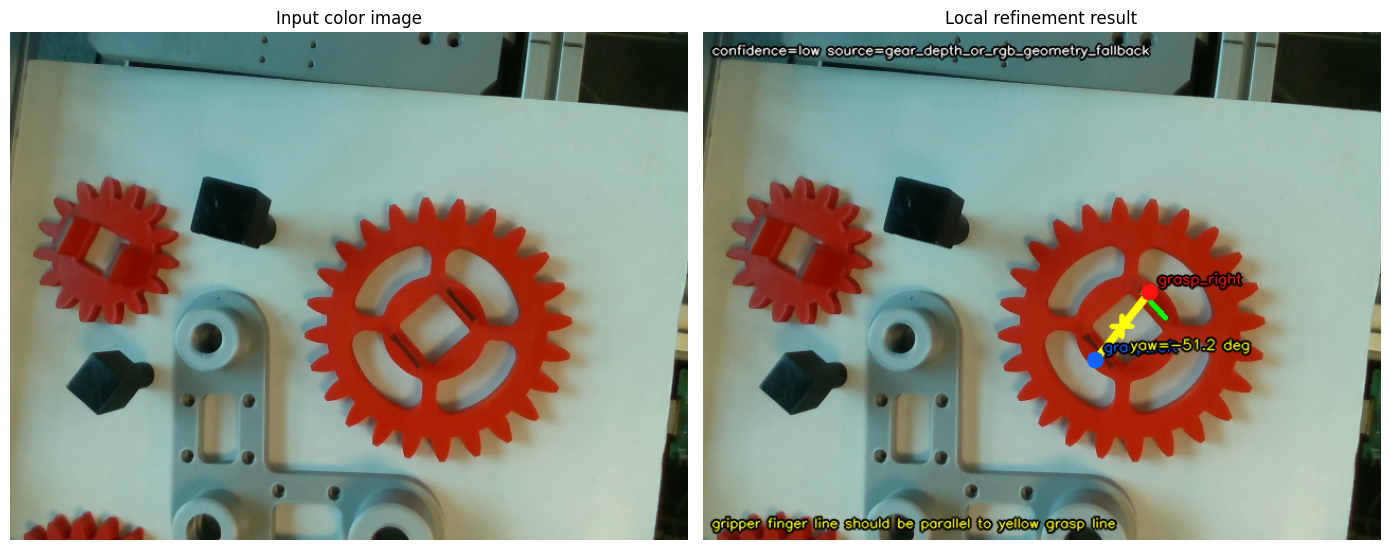

In [67]:
def save_local_outputs(
    result_dict,
    annotated_image,
    debug_images,
    json_path=OUTPUT_JSON,
    csv_path=OUTPUT_CSV,
    annotated_path=OUTPUT_ANNOTATED,
):
    json_path, csv_path, annotated_path = map(
        Path, (json_path, csv_path, annotated_path)
    )
    json_path.parent.mkdir(parents=True, exist_ok=True)
    with json_path.open("w", encoding="utf-8") as file:
        json.dump(result_dict, file, ensure_ascii=False, allow_nan=False, indent=2)

    rows = []
    for name, pixel in result_dict.get("pixel_points", {}).items():
        camera = result_dict.get("camera_points", {}).get(name, {})
        rows.append({
            "timestamp_sec": result_dict.get("timestamp_sec"),
            "target_type": result_dict.get("target_type"),
            "result_type": result_dict.get("result_type"),
            "point_name": name,
            "u": pixel.get("u"),
            "v": pixel.get("v"),
            "radius_px": pixel.get("radius_px"),
            "yaw_deg": result_dict.get("yaw_deg"),
            "depth_valid": camera.get("depth_valid"),
            "depth_m": camera.get("depth_m"),
            "depth_source": camera.get("depth_source"),
            "top_surface_depth_m": result_dict.get("top_surface_depth_m"),
            "top_surface_area_px": result_dict.get("top_surface_area_px"),
            "camera_x_m": camera.get("camera_x_m"),
            "camera_y_m": camera.get("camera_y_m"),
            "camera_z_m": camera.get("camera_z_m"),
            "camera_frame_id": camera.get("camera_frame_id", CAMERA_FRAME_ID),
            "confidence": result_dict.get("confidence"),
            "rule_note": result_dict.get("rule_note"),
        })
    fieldnames = [
        "timestamp_sec", "target_type", "result_type", "point_name",
        "u", "v", "radius_px", "yaw_deg", "depth_valid", "depth_m",
        "depth_source", "top_surface_depth_m", "top_surface_area_px",
        "camera_x_m", "camera_y_m", "camera_z_m",
        "camera_frame_id", "confidence", "rule_note",
    ]
    with csv_path.open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    if not cv2.imwrite(str(annotated_path), annotated_image):
        raise OSError(f"Could not save {annotated_path}")
    for name, image in debug_images.items():
        if isinstance(image, np.ndarray) and image.ndim in (2, 3):
            cv2.imwrite(str(json_path.parent / f"{name}.png"), image)
    return {
        "json": str(json_path),
        "csv": str(csv_path),
        "annotated": str(annotated_path),
    }


color_image_bgr, depth_image_m, intrinsics = load_selected_input()
result_dict, annotated_image, debug_images = run_local_refinement(
    color_image_bgr, depth_image_m, intrinsics, TARGET_TYPE
)
saved_paths = save_local_outputs(result_dict, annotated_image, debug_images)

print(json.dumps(result_dict, ensure_ascii=False, indent=2))
print("Saved:", saved_paths)
if intrinsics is None:
    print(
        "NOTE: pixel detection ran, but camera XYZ is invalid because true "
        "color intrinsics were not supplied."
    )

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Input color image")
axes[1].imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Local refinement result")
for axis in axes:
    axis.axis("off")
figure.tight_layout()
plt.show()


### Operational reminder

- The right-side depth colormap in old screenshots is visualization only.
- Real 3D coordinates must use aligned raw depth in meters.
- Base-hole pixel coordinates use the black-hole centers, but hole depth uses the surrounding silver-ring median.
- All XYZ values are in `camera_color_optical_frame`, never robot base frame.

In [68]:
# RealSense D435i live local RGB-D grasp-refinement viewer.
# Run this cell after all function cells above have been executed.

import time


def run_realsense_local_refinement_live(target_type=TARGET_TYPE):
    """Show the existing local detector on aligned live RGB-D and keep the latest result in memory."""
    try:
        import pyrealsense2 as rs_live
    except ImportError:
        print(
            "pyrealsense2 is not installed. Install the RealSense Python "
            "package before running this cell."
        )
        return

    if target_type not in VALID_TARGET_TYPES:
        print(
            f"Unsupported TARGET_TYPE={target_type!r}. "
            f"Choose one of: {sorted(VALID_TARGET_TYPES)}"
        )
        return

    window_name = "RealSense Local Grasp Refinement Live"
    pipeline = rs_live.pipeline()
    config = rs_live.config()
    config.enable_stream(
        rs_live.stream.color, 640, 480, rs_live.format.bgr8, 30
    )
    config.enable_stream(
        rs_live.stream.depth, 640, 480, rs_live.format.z16, 30
    )

    pipeline_started = False
    paused = False
    display_mode_index = 0
    previous_gray = None
    stable_frame_count = 0
    previous_time = None
    fps = 0.0
    last_base_views = {}
    last_available_modes = []
    last_mode_name = "annotated_result"
    latest_result = None
    latest_annotated = None
    latest_debug_images = None
    last_status = {
        "motion_score": 0.0,
        "state": "MOVING",
        "confidence": "unknown",
        "depth_valid": False,
    }

    try:
        try:
            profile = pipeline.start(config)
            pipeline_started = True
            align_to_color = rs_live.align(rs_live.stream.color)
            depth_scale = float(
                profile.get_device()
                .first_depth_sensor()
                .get_depth_scale()
            )
        except Exception as exc:
            print(
                "Could not start RealSense D435i. Check that the camera is "
                f"connected and not used by another process. Details: {exc}"
            )
            return

        print(
            f"Local live target: {target_type}. "
            "Controls: q/ESC quit, space pause/resume, d cycle debug views."
        )
        cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)

        # Allow auto-exposure to settle before evaluating motion and detection.
        for _ in range(max(1, int(LIVE_WARMUP_FRAMES))):
            pipeline.wait_for_frames(timeout_ms=5000)

        while True:
            if not paused:
                frames = pipeline.wait_for_frames(timeout_ms=5000)
                aligned_frames = align_to_color.process(frames)
                color_frame = aligned_frames.get_color_frame()
                depth_frame = aligned_frames.get_depth_frame()
                if not color_frame or not depth_frame:
                    print("Aligned color/depth frame unavailable; retrying.")
                    continue

                color_bgr = np.asanyarray(color_frame.get_data()).copy()
                depth_raw = np.asanyarray(depth_frame.get_data())
                depth_image_m = (
                    depth_raw.astype(np.float32) * depth_scale
                )
                color_intr = (
                    color_frame.profile
                    .as_video_stream_profile()
                    .intrinsics
                )
                intrinsics = {
                    "fx": float(color_intr.fx),
                    "fy": float(color_intr.fy),
                    "ppx": float(color_intr.ppx),
                    "ppy": float(color_intr.ppy),
                }

                result, annotated, debug_images = run_local_refinement(
                    color_bgr,
                    depth_image_m,
                    intrinsics,
                    target_type,
                )
                latest_result = result
                latest_annotated = annotated.copy()
                latest_debug_images = {
                    name: image.copy() if isinstance(image, np.ndarray) else image
                    for name, image in debug_images.items()
                }

                gray = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2GRAY)
                if previous_gray is None:
                    motion_score = 0.0
                    stable_frame_count = 0
                else:
                    motion_score = float(
                        cv2.mean(
                            cv2.absdiff(gray, previous_gray)
                        )[0]
                    )
                    stable_frame_count = (
                        stable_frame_count + 1
                        if motion_score < 2.0
                        else 0
                    )
                previous_gray = gray
                state = (
                    "STABLE"
                    if stable_frame_count >= 10
                    else "MOVING"
                )

                now = time.perf_counter()
                if previous_time is not None:
                    instant_fps = 1.0 / max(
                        now - previous_time, 1e-6
                    )
                    fps = (
                        instant_fps
                        if fps <= 0.0
                        else 0.85 * fps + 0.15 * instant_fps
                    )
                previous_time = now

                base_views = {
                    "annotated_result": annotated,
                    "color_image": color_bgr,
                }
                for name, image in debug_images.items():
                    if (
                        isinstance(image, np.ndarray)
                        and image.size > 0
                    ):
                        base_views[name] = image

                # This depth colormap is display-only. Detection and XYZ use
                # aligned raw depth_image_m above.
                depth_display = np.zeros_like(depth_raw, dtype=np.uint8)
                valid_depth = (
                    np.isfinite(depth_image_m)
                    & (depth_image_m > 0)
                )
                if np.any(valid_depth):
                    valid_values = depth_image_m[valid_depth]
                    near = float(np.percentile(valid_values, 5))
                    far = float(np.percentile(valid_values, 95))
                    if far > near:
                        normalized = np.clip(
                            (depth_image_m - near)
                            / (far - near),
                            0.0,
                            1.0,
                        )
                        depth_display = np.uint8(
                            255.0 * (1.0 - normalized)
                        )
                        depth_display[~valid_depth] = 0
                base_views["depth_colormap_display_only"] = (
                    cv2.applyColorMap(
                        depth_display, cv2.COLORMAP_TURBO
                    )
                )

                preferred_modes = [
                    "annotated_result",
                    "color_image",
                    "red_mask",
                    "black_mask",
                    "object_mask",
                    "black_marker_mask",
                    "black_marker_search_mask",
                    "black_marker_candidates",
                    "selected_black_markers",
                    "base_mask",
                    "hole_search_mask",
                    "valid_depth_mask",
                    "top_surface_mask",
                    "top_surface_components",
                    "selected_grasp_components",
                    "selected_contours_mask",
                    "depth_colormap_display_only",
                ]
                available_modes = [
                    name
                    for name in preferred_modes
                    if name in base_views
                ]
                for name in base_views:
                    if name not in available_modes:
                        available_modes.append(name)
                display_mode_index %= len(available_modes)

                last_base_views = base_views
                last_available_modes = available_modes
                last_mode_name = available_modes[display_mode_index]
                last_status = {
                    "motion_score": motion_score,
                    "state": state,
                    "confidence": result.get(
                        "confidence", "unknown"
                    ),
                    "depth_valid": bool(
                        result.get("depth_valid", False)
                    ),
                }

            if not last_base_views:
                continue

            if not paused and last_available_modes:
                display_mode_index %= len(last_available_modes)
                last_mode_name = last_available_modes[
                    display_mode_index
                ]
            view = last_base_views[last_mode_name]
            if view.ndim == 2:
                view = cv2.cvtColor(view, cv2.COLOR_GRAY2BGR)
            else:
                view = view.copy()

            state = last_status["state"]
            status_color = (
                (40, 220, 40)
                if state == "STABLE"
                else (0, 165, 255)
            )
            status_text = (
                f"FPS {fps:5.1f}  target {target_type}  "
                f"{state}  motion {last_status['motion_score']:.2f}"
            )
            result_text = (
                f"confidence {last_status['confidence']}  "
                f"depth_valid {last_status['depth_valid']}  "
                f"view {last_mode_name}"
            )
            cv2.putText(
                view,
                status_text,
                (10, 24),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                (0, 0, 0),
                3,
                cv2.LINE_AA,
            )
            cv2.putText(
                view,
                status_text,
                (10, 24),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                status_color,
                1,
                cv2.LINE_AA,
            )
            cv2.putText(
                view,
                result_text,
                (10, 47),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.46,
                (255, 255, 255),
                1,
                cv2.LINE_AA,
            )
            if paused:
                cv2.putText(
                    view,
                    "PAUSED",
                    (10, 72),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    (0, 0, 255),
                    2,
                    cv2.LINE_AA,
                )

            cv2.imshow(window_name, view)
            key = cv2.waitKey(1 if not paused else 30) & 0xFF
            if key in (ord("q"), 27):
                break
            if key == ord(" "):
                paused = not paused
                print(
                    "Local live view paused."
                    if paused
                    else "Local live view resumed."
                )
            elif key == ord("d") and last_available_modes:
                display_mode_index = (
                    display_mode_index + 1
                ) % len(last_available_modes)
                last_mode_name = last_available_modes[
                    display_mode_index
                ]

    except KeyboardInterrupt:
        print("Local live detection interrupted.")
    except Exception as exc:
        print(f"RealSense local live detection stopped: {exc}")
    finally:
        global last_live_result, last_live_annotated_image, last_live_debug_images, result_dict
        if latest_result is not None:
            last_live_result = latest_result
            last_live_annotated_image = latest_annotated
            last_live_debug_images = latest_debug_images
            result_dict = latest_result
            print("Latest live result stored in `last_live_result` and `result_dict`.")
        if pipeline_started:
            pipeline.stop()
        cv2.destroyAllWindows()
        print("RealSense local live detection closed.")


run_realsense_local_refinement_live(TARGET_TYPE)


Local live target: gear_large. Controls: q/ESC quit, space pause/resume, d cycle debug views.
Local live view paused.
Latest live result stored in `last_live_result` and `result_dict`.
RealSense local live detection closed.


In [69]:
# Display current detection points in camera coordinates.
# Run this after the offline detection cell, or after a saved local_refinement_result.json exists.

import pandas as pd

POINT_ROLE = {
    "gear_center": "center",
    "rect_center": "center",
    "screw_center": "center",
    "top_surface_center": "center/top_surface",
    "hole_large": "base_hole",
    "hole_small": "base_hole",
    "hole_screw": "base_hole",
    "grasp_left": "grasp",
    "grasp_right": "grasp",
    "grasp_midpoint": "grasp",
}

try:
    current_result = last_live_result
    source_name = "in-memory last_live_result"
except NameError:
    try:
        current_result = result_dict
        source_name = "in-memory result_dict"
    except NameError:
        if not OUTPUT_JSON.exists():
            raise FileNotFoundError(
                f"没有找到 {OUTPUT_JSON}，请先运行检测 cell 生成 result_dict。"
            )
        current_result = json.loads(OUTPUT_JSON.read_text(encoding="utf-8-sig"))
        source_name = str(OUTPUT_JSON)

rows = []
pixel_points = current_result.get("pixel_points", {}) or {}
camera_points = current_result.get("camera_points", {}) or {}

preferred_order = [
    "gear_center", "rect_center", "screw_center", "top_surface_center",
    "hole_large", "hole_small", "hole_screw",
    "grasp_left", "grasp_right", "grasp_midpoint",
]
ordered_names = [name for name in preferred_order if name in pixel_points or name in camera_points]
ordered_names += [
    name for name in pixel_points
    if name not in ordered_names
]

for name in ordered_names:
    pixel = pixel_points.get(name, {}) or {}
    camera = camera_points.get(name, {}) or {}
    rows.append({
        "point_name": name,
        "role": POINT_ROLE.get(name, "other"),
        "u_px": pixel.get("u"),
        "v_px": pixel.get("v"),
        "depth_valid": camera.get("depth_valid"),
        "depth_m": camera.get("depth_m"),
        "camera_x_m": camera.get("camera_x_m"),
        "camera_y_m": camera.get("camera_y_m"),
        "camera_z_m": camera.get("camera_z_m"),
        "depth_source": camera.get("depth_source"),
        "camera_frame_id": camera.get("camera_frame_id", CAMERA_FRAME_ID),
    })

print("Source:", source_name)
print("target_type:", current_result.get("target_type"))
print("result_type:", current_result.get("result_type"))
print("status:", current_result.get("status"))
print("confidence:", current_result.get("confidence"))
print("yaw_deg:", current_result.get("yaw_deg"))

if not rows:
    print("当前结果没有可显示的 pixel_points/camera_points。请确认检测成功且 result_dict 已更新。")
else:
    point_table = pd.DataFrame(rows)
    display(point_table)

    valid_xyz = point_table[point_table["depth_valid"] == True]
    if valid_xyz.empty:
        print("没有有效 camera XYZ；请确认使用 aligned raw depth 和真实 color intrinsics。")
    else:
        print("有效 camera XYZ 点数:", len(valid_xyz))


Source: in-memory last_live_result
target_type: gear_large
result_type: grasp
status: ok
confidence: low
yaw_deg: None


,point_name,role,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,depth_source,camera_frame_id
0,gear_center,center,382.661461,284.986334,True,0.3280,0.034951,0.016077,0.3280,center_window_median,camera_color_optical_frame
1,grasp_left,grasp,345.000000,241.000000,True,0.3070,0.013614,-0.007297,0.3070,None,camera_color_optical_frame
2,grasp_right,grasp,404.000000,340.000000,True,0.3000,0.042542,0.042014,0.3000,None,camera_color_optical_frame
3,grasp_midpoint,grasp,374.500000,290.500000,True,0.3035,0.028249,0.017645,0.3035,None,camera_color_optical_frame


有效 camera XYZ 点数: 4


In [70]:
# Convert the detected 3D grasp line from camera frame to robot base frame.
# This is an independent test cell; it does not change the detector output.
# Fill T_BASE_GRIPPER with the robot pose captured at the same time as the RGB-D image.

HAND_EYE_RESULT_PATH = Path("cam_calibration/config/hand_eye_result.json")
T_BASE_GRIPPER = None  # Replace with the synchronized 4x4 T_base_gripper.
GRIPPER_BASE_YAW_OFFSET_DEG = 0.0

# Example only:
T_BASE_GRIPPER = np.array([
    [0.996839988, -0.079426334, -0.001222903, 0.475983832],
    [-0.079288381, -0.995810072, 0.045559338, 0.021302204],
    [-0.004836390, -0.045318408, -0.998960886, 0.434017867],
    [0.000000000, 0.000000000, 0.000000000, 1.000000000],

], dtype=np.float64)


def _validated_transform_for_yaw(T, name):
    matrix = np.asarray(T, dtype=np.float64)
    if matrix.shape != (4, 4) or not np.all(np.isfinite(matrix)):
        raise ValueError(f"{name} must be a finite 4x4 matrix")
    if not np.allclose(matrix[3], [0.0, 0.0, 0.0, 1.0], atol=1e-6):
        raise ValueError(f"{name} has an invalid homogeneous last row")
    rotation = matrix[:3, :3]
    if not np.allclose(rotation.T @ rotation, np.eye(3), atol=1e-3):
        raise ValueError(f"{name} rotation is not orthonormal")
    if not np.isclose(np.linalg.det(rotation), 1.0, atol=1e-3):
        raise ValueError(f"{name} rotation determinant must be +1")
    return matrix


def _camera_xyz_from_grasp_result(grasp_result, point_name):
    point = grasp_result.get(point_name) or {}
    if not point:
        point = (grasp_result.get("camera_points") or {}).get(point_name) or {}
    xyz = [point.get("camera_x_m"), point.get("camera_y_m"), point.get("camera_z_m")]
    if any(value is None for value in xyz):
        raise ValueError(
            f"{point_name} has no valid camera XYZ; run detection with aligned raw depth "
            "and real color intrinsics first"
        )
    xyz = np.asarray(xyz, dtype=np.float64)
    if not np.all(np.isfinite(xyz)):
        raise ValueError(f"{point_name} camera XYZ contains invalid values")
    return xyz


def compute_grasp_yaw_in_base(
    grasp_result, T_base_gripper, T_gripper_camera, yaw_offset_deg=0.0
):
    """Transform both grasp endpoints and compute their line yaw in base XY."""
    T_bg = _validated_transform_for_yaw(T_base_gripper, "T_base_gripper")
    T_gc = _validated_transform_for_yaw(T_gripper_camera, "T_gripper_camera")
    T_base_camera = T_bg @ T_gc

    left_camera = _camera_xyz_from_grasp_result(grasp_result, "grasp_left")
    right_camera = _camera_xyz_from_grasp_result(grasp_result, "grasp_right")
    left_base = (T_base_camera @ np.r_[left_camera, 1.0])[:3]
    right_base = (T_base_camera @ np.r_[right_camera, 1.0])[:3]
    line_base = right_base - left_base
    line_xy_length = float(np.hypot(line_base[0], line_base[1]))
    if line_xy_length < 1e-6:
        raise ValueError("transformed grasp line has near-zero length in base XY")

    yaw_directed = float(np.degrees(np.arctan2(line_base[1], line_base[0])))
    yaw_directed = float(((yaw_directed + yaw_offset_deg + 180.0) % 360.0) - 180.0)
    # A parallel-finger line is an axis: yaw and yaw+180 degrees are equivalent.
    yaw_axis = float(((yaw_directed + 90.0) % 180.0) - 90.0)
    midpoint_base = 0.5 * (left_base + right_base)
    return {
        "target_type": grasp_result.get("target_type"),
        "grasp_left_base_m": [float(x) for x in left_base],
        "grasp_right_base_m": [float(x) for x in right_base],
        "grasp_midpoint_base_m": [float(x) for x in midpoint_base],
        "grasp_line_vector_base_m": [float(x) for x in line_base],
        "grasp_line_length_base_xy_m": line_xy_length,
        "yaw_base_deg_directed": yaw_directed,
        "yaw_base_deg_axis": yaw_axis,
        "yaw_frame": "robot_base_xy_frame",
        "yaw_definition": (
            "atan2(right_base_y-left_base_y, right_base_x-left_base_x); "
            "gripper finger line should be parallel to this line"
        ),
        "yaw_offset_deg": float(yaw_offset_deg),
    }


if T_BASE_GRIPPER is None:
    print("请先填写拍照时同步获取的 T_BASE_GRIPPER，然后重新运行本 cell。")
else:
    hand_eye_data = json.loads(HAND_EYE_RESULT_PATH.read_text(encoding="utf-8"))
    T_GRIPPER_CAMERA = hand_eye_data.get("T_gripper_camera")
    if T_GRIPPER_CAMERA is None:
        raise ValueError(f"{HAND_EYE_RESULT_PATH} does not contain T_gripper_camera")
    try:
        grasp_result_for_base_yaw = last_live_result
    except NameError:
        grasp_result_for_base_yaw = result_dict
    base_grasp_pose = compute_grasp_yaw_in_base(
        grasp_result_for_base_yaw,
        T_BASE_GRIPPER,
        T_GRIPPER_CAMERA,
        GRIPPER_BASE_YAW_OFFSET_DEG,
    )
    print(json.dumps(base_grasp_pose, ensure_ascii=False, indent=2))


{
  "target_type": "gear_large",
  "grasp_left_base_m": [
    0.41250861394109933,
    0.028562823686900548,
    0.06725112981566389
  ],
  "grasp_right_base_m": [
    0.4640028422830266,
    0.053188612784325295,
    0.0749543525504755
  ],
  "grasp_midpoint_base_m": [
    0.4382557281120629,
    0.04087571823561292,
    0.0711027411830697
  ],
  "grasp_line_vector_base_m": [
    0.05149422834192724,
    0.024625789097424747,
    0.00770322273481161
  ],
  "grasp_line_length_base_xy_m": 0.05707963771084559,
  "yaw_base_deg_directed": 25.558257913402286,
  "yaw_base_deg_axis": 25.558257913402286,
  "yaw_frame": "robot_base_xy_frame",
  "yaw_definition": "atan2(right_base_y-left_base_y, right_base_x-left_base_x); gripper finger line should be parallel to this line",
  "yaw_offset_deg": 0.0
}
